In [2]:
import qiskit
print(qiskit.__version__)

0.45.3


In [3]:
from gidnet.qubitreuse import GidNET
print("GidNET import successful")

GidNET import successful


In [4]:
import qiskit
import inspect

print("Qiskit version:", qiskit.__version__)
print("GidNET file:", inspect.getfile(GidNET))

Qiskit version: 0.45.3
GidNET file: C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\gidnet\qubitreuse.py


In [5]:
from pathlib import Path

BENCHMARK_DIR = Path(
    r"C:\Users\ASUS\Documents\Quantum computing\Qiskit\CaQR-main\CaQR-main\benchmarks"
)

print("Exists:", BENCHMARK_DIR.exists())

matches = list(BENCHMARK_DIR.rglob("system9.qasm"))
print(matches)

Exists: True
[WindowsPath('C:/Users/ASUS/Documents/Quantum computing/Qiskit/CaQR-main/CaQR-main/benchmarks/system9.qasm')]


In [6]:
from qiskit import QuantumCircuit

system9_path = BENCHMARK_DIR / "system9.qasm"

qc = QuantumCircuit.from_qasm_file(system9_path)

print(qc)
print("Qubits:", qc.num_qubits)
print("Clbits:", qc.num_clbits)
print("Depth:", qc.depth())
print("Ops:", qc.count_ops())

      ┌───┐┌───┐                      ┌─────┐          ┌───┐               »
 q_0: ┤ T ├┤ X ├───────■───────────■──┤ Tdg ├───────■──┤ X ├──■────────────»
      ├───┤└─┬─┘┌───┐  │  ┌─────┐┌─┴─┐├─────┤┌───┐  │  └─┬─┘┌─┴─┐┌───┐     »
 q_1: ┤ T ├──■──┤ X ├──┼──┤ Tdg ├┤ X ├┤ Tdg ├┤ X ├──┼────■──┤ X ├┤ T ├─────»
      ├───┤     └─┬─┘  │  └─────┘└───┘└─────┘└─┬─┘  │       └───┘├───┤     »
 q_2: ┤ T ├───────┼────┼───────────────────────┼────┼────────────┤ X ├─────»
      ├───┤       │    │                       │    │            └─┬─┘     »
 q_3: ┤ T ├───────┼────┼───────────────────────┼────┼──────────────┼───────»
      ├───┤       │    │                       │    │              │       »
 q_4: ┤ T ├───────┼────┼───────────────────────┼────┼──────────────┼───────»
      ├───┤       │    │                       │    │              │       »
 q_5: ┤ T ├───────┼────┼───────────────────────┼────┼──────────────┼───────»
      ├───┤       │    │                       │    │              │       »

In [7]:
import random
import numpy as np

random.seed(0)
np.random.seed(0)

g = GidNET(qc)

gidnet_circ = g.compile_to_dynamic_circuit(
    iterations=20,
    draw=False
)

print("GidNET run finished")
print("Output qubits:", gidnet_circ.num_qubits)
print("Output clbits:", gidnet_circ.num_clbits)
print("Output depth:", gidnet_circ.depth())
print("Output ops:", gidnet_circ.count_ops())

GidNET run finished
Output qubits: 7
Output clbits: 16
Output depth: 163
Output ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40, 'reset': 5})


In [8]:
print(g.__dict__.keys())

dict_keys(['circuit', 'circuit_dag', 'biadjacency_matrix', 'candidate_matrix', 'candidate_matrix_copy', 'qubit_reuse_sequences', 'reuse_edges', 'reset_after_nodes', 'circuit_dag_with_reuse_edges', 'dynamic_circuit', 'dynamic_circuit_dag', 'dynamic_circuit_width', 'list_of_computed_reuse_sequences'])


In [9]:
attrs_to_check = [
    "qubit_reuse_sequences",
    "reuse_edges",
    "reset_after_nodes",
    "list_of_computed_reuse_sequences",
    "dynamic_circuit_width"
]

for attr in attrs_to_check:
    value = getattr(g, attr)
    print(f"\n--- {attr} ---")
    print("type:", type(value))
    print("value:", value)


--- qubit_reuse_sequences ---
type: <class 'list'>
value: [[4, 22, 28, 31, 15, 25, 19, 18, 26, 29, 16, 27, 24, 30, 23, 20, 14, 17, 13, 12, 21, 6, 8], [0, 2, 5, 7], [1], [3], [9], [10], [11]]

--- reuse_edges ---
type: <class 'list'>
value: [(DAGOutNode(wire=Qubit(QuantumRegister(16, 'q'), 4)), DAGInNode(wire=Clbit(ClassicalRegister(16, 'c'), 6))), (DAGOutNode(wire=Clbit(ClassicalRegister(16, 'c'), 6)), DAGInNode(wire=Clbit(ClassicalRegister(16, 'c'), 12))), (DAGOutNode(wire=Clbit(ClassicalRegister(16, 'c'), 12)), DAGInNode(wire=Clbit(ClassicalRegister(16, 'c'), 15))), (DAGOutNode(wire=Clbit(ClassicalRegister(16, 'c'), 15)), DAGInNode(wire=Qubit(QuantumRegister(16, 'q'), 15))), (DAGOutNode(wire=Qubit(QuantumRegister(16, 'q'), 15)), DAGInNode(wire=Clbit(ClassicalRegister(16, 'c'), 9))), (DAGOutNode(wire=Clbit(ClassicalRegister(16, 'c'), 9)), DAGInNode(wire=Clbit(ClassicalRegister(16, 'c'), 3))), (DAGOutNode(wire=Clbit(ClassicalRegister(16, 'c'), 3)), DAGInNode(wire=Clbit(ClassicalRegist

In [10]:
import inspect

source = inspect.getsource(GidNET)

for i, line in enumerate(source.splitlines(), start=1):
    if (
        "qubit_reuse_sequences" in line
        or "reuse_edges" in line
        or "list_of_computed_reuse_sequences" in line
    ):
        print(f"{i}: {line}")

26:         self.qubit_reuse_sequences = None
27:         self.reuse_edges = None
29:         self.circuit_dag_with_reuse_edges = None
33:         self.list_of_computed_reuse_sequences = []  # this keeps track of all the reuse sequences computed so far. It is used to determine the optimal iterations to use
65:         self.qubit_reuse_sequences = self.compute_optimized_reuse_sequences(iterations)
68:         if self.qubit_reuse_sequences is None:
72:         self.add_qubit_reuse_edges()
75:         barrier_nodes = [node for node in list(self.circuit_dag_with_reuse_edges.nodes()) 
78:             self.circuit_dag_with_reuse_edges.remove_op_node(op_node)
81:         if len(list(self.circuit_dag_with_reuse_edges.nodes())) > len(list(self.circuit_dag_with_reuse_edges.topological_nodes())):
86:         for new_qubit in range(len(self.qubit_reuse_sequences)):
87:             for old_qubit in self.qubit_reuse_sequences[new_qubit]:
92:         num_qubits = len(self.qubit_reuse_sequences)
99:  

In [11]:
import inspect

print(inspect.getsource(GidNET.compute_optimized_reuse_sequences))

    def compute_optimized_reuse_sequences(self, iterations: int) -> Optional[List[List[int]]]:
        """
        Computes optimized qubit reuse sequences using the GidNET Qubit Reuse Algorithm.

        This method iteratively finds and optimizes qubit reuse sequences while maintaining 
        an updated candidate matrix throughout the process.

        Args:
        iterations (int): Number of iterations for optimization of GidNET Algorithm.

        Returns:
            Optional[List[List[int]]]: List of optimized reuse sequences or None if the circuit is irreducible.
        """
        # Reset the candidate matrix to its original state before optimization
        self.candidate_matrix = np.copy(self.candidate_matrix_copy)
        n = self.candidate_matrix.shape[0]
        U = [[i] for i in range(n)]  # Initialize trivial reuse sets (one per qubit)

        if np.all(self.candidate_matrix == 0):
            self.dynamic_circuit_width = self.circuit.num_qubits
            return N

In [12]:
print("candidate_matrix shape:", g.candidate_matrix.shape)
print("candidate_matrix_copy shape:", g.candidate_matrix_copy.shape)

print("circuit qubits:", qc.num_qubits)
print("circuit clbits:", qc.num_clbits)

candidate_matrix shape: (32, 32)
candidate_matrix_copy shape: (32, 32)
circuit qubits: 16
circuit clbits: 16


In [13]:
import inspect

print(inspect.getsource(GidNET.__init__))

    def __init__(self, circuit: QuantumCircuit):
        """Initializes the GidNET algorithm with a given quantum circuit.
        
        Args:
            circuit (QuantumCircuit): The input quantum circuit to be analyzed and transformed.
        """
        self.circuit = circuit
        self.circuit_dag = circuit_to_dag(self.circuit)  # Convert the circuit to a DAG representation
        
        # compute the candidate matrix
        self.biadjacency_matrix, self.candidate_matrix = self.compute_intial_biadjacency_and_candidate_matrix()
        # self.biadjacency_matrix, self.candidate_matrix = None, None
        # self.candidate_matrix_copy = None
        self.candidate_matrix_copy = np.copy(self.candidate_matrix) # make a copy of the candidate matrix
        self.qubit_reuse_sequences = None
        self.reuse_edges = None
        self.reset_after_nodes = []
        self.circuit_dag_with_reuse_edges = None
        self.dynamic_circuit = None
        self.dynamic_circuit_dag = No

In [14]:
import inspect

print(
    inspect.getsource(
        GidNET.compute_intial_biadjacency_and_candidate_matrix
    )
)

    def compute_intial_biadjacency_and_candidate_matrix(self) -> Tuple[np.ndarray, np.ndarray]:
        """
        Computes the biadjacency and candidate matrices of the simplified bipartite graph 
        of the quantum circuit by searching for connections between the input qubits and
        the output qubits of the quantum circuit.
    
        Returns:
            Tuple[np.ndarray, np.ndarray]:
                - biadjacency_matrix: A matrix representing direct connections between input and output qubits.
                - candidate_matrix: A matrix representing potential qubit reuse based on missing direct connections.
        """
        # Create a temporary copy of the circuit DAG without final measurements
        tmp_circuit = copy.deepcopy(self.circuit)
        tmp_circuit.remove_final_measurements()
        tmp_circuit_dag = circuit_to_dag(tmp_circuit)
        
        # Convert DAG to NetworkX graph
        graph = self._to_networkx(tmp_circuit_dag)
        
        # Ident

In [15]:
import inspect

src = inspect.getsource(GidNET.compile_to_dynamic_circuit)
lines = src.splitlines()

for i, line in enumerate(lines, start=1):
    print(f"{i:3}: {line}")

  1:     def compile_to_dynamic_circuit(self, iterations: int = 10, draw: bool = False) -> QuantumCircuit:
  2:         """
  3:         Converts a static quantum circuit into a dynamic quantum circuit.
  4: 
  5:         This method optimizes qubit reuse by modifying the DAG structure of the circuit. It:
  6:         - Computes the DAG and candidate matrix of the circuit.
  7:         - Computes optimized qubit reuse sequences.
  8:         - Adds edges to the DAG based on these sequences.
  9:         - Removes barriers to enable topological sorting.
 10:         - Reorders qubits based on the reuse mappings.
 11:         - Constructs the final transformed dynamic quantum circuit.
 12: 
 13:         Args:
 14:             iterations (int, optional): Number of iterations for the GidNET optimization algorithm. Default is 10.
 15:             draw (bool, optional): Whether to display the transformed dynamic circuit. Default is False.
 16: 
 17:         Returns:
 18:             QuantumC

In [16]:
from qiskit import QuantumCircuit

def make_quantum_only(circuit):
    new_circuit = QuantumCircuit(circuit.num_qubits)

    for item in circuit.data:
        # Compatible with Qiskit 0.45
        operation = item.operation
        qargs = item.qubits
        cargs = item.clbits

        if len(cargs) != 0:
            raise ValueError(
                f"Found an operation with classical bits: {operation.name}"
            )

        q_indices = [
            circuit.find_bit(q).index
            for q in qargs
        ]

        new_circuit.append(
            operation.copy(),
            q_indices,
            []
        )

    return new_circuit


qc_clean = make_quantum_only(qc)

print("Original:")
print("  qubits:", qc.num_qubits)
print("  clbits:", qc.num_clbits)
print("  depth:", qc.depth())
print("  ops:", qc.count_ops())

print("\nClean:")
print("  qubits:", qc_clean.num_qubits)
print("  clbits:", qc_clean.num_clbits)
print("  depth:", qc_clean.depth())
print("  ops:", qc_clean.count_ops())

Original:
  qubits: 16
  clbits: 16
  depth: 127
  ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40})

Clean:
  qubits: 16
  clbits: 0
  depth: 127
  ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40})


In [17]:
import random
import numpy as np

random.seed(0)
np.random.seed(0)

g_clean = GidNET(qc_clean)

gidnet_clean_circ = g_clean.compile_to_dynamic_circuit(
    iterations=20,
    draw=False
)

print("GidNET clean run finished")

print("\nCandidate matrix shape:")
print(g_clean.candidate_matrix.shape)

print("\nDynamic circuit:")
print("qubits:", gidnet_clean_circ.num_qubits)
print("clbits:", gidnet_clean_circ.num_clbits)
print("depth:", gidnet_clean_circ.depth())
print("ops:", gidnet_clean_circ.count_ops())

print("\nReuse sequences:")
print(g_clean.qubit_reuse_sequences)

print("\nMax index in reuse sequences:")
print(max(max(seq) for seq in g_clean.qubit_reuse_sequences))

GidNET clean run finished

Candidate matrix shape:
(16, 16)

Dynamic circuit:
qubits: 7
clbits: 0
depth: 162
ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40, 'reset': 6})

Reuse sequences:
[[10, 15, 14, 12, 13], [4, 6, 8], [2, 5, 7], [0, 11], [1], [3], [9]]

Max index in reuse sequences:
15


In [18]:
active_qubits = set()

for item in qc_clean.data:
    for q in item.qubits:
        active_qubits.add(qc_clean.find_bit(q).index)

active_qubits = sorted(active_qubits)

print("Active qubits:", active_qubits)
print("Number of active qubits:", len(active_qubits))

idle_qubits = sorted(set(range(qc_clean.num_qubits)) - set(active_qubits))

print("Idle qubits:", idle_qubits)
print("Number of idle qubits:", len(idle_qubits))

Active qubits: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Number of active qubits: 12
Idle qubits: [12, 13, 14, 15]
Number of idle qubits: 4


In [19]:
from qiskit import QuantumCircuit

def remove_idle_qubits(circuit):
    active = sorted({
        circuit.find_bit(q).index
        for item in circuit.data
        for q in item.qubits
    })

    old_to_new = {
        old_idx: new_idx
        for new_idx, old_idx in enumerate(active)
    }

    compact = QuantumCircuit(len(active))

    for item in circuit.data:
        operation = item.operation
        qargs = item.qubits
        cargs = item.clbits

        if cargs:
            raise ValueError(
                f"Classical operation found: {operation.name}"
            )

        new_qargs = [
            old_to_new[circuit.find_bit(q).index]
            for q in qargs
        ]

        compact.append(
            operation.copy(),
            new_qargs,
            []
        )

    return compact, old_to_new


qc_compact, old_to_new = remove_idle_qubits(qc_clean)

print("Old -> new mapping:", old_to_new)

print("\nBefore removing idle qubits:")
print("qubits:", qc_clean.num_qubits)
print("depth:", qc_clean.depth())
print("ops:", qc_clean.count_ops())

print("\nAfter removing idle qubits:")
print("qubits:", qc_compact.num_qubits)
print("clbits:", qc_compact.num_clbits)
print("depth:", qc_compact.depth())
print("ops:", qc_compact.count_ops())

Old -> new mapping: {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5, 6: 6, 7: 7, 8: 8, 9: 9, 10: 10, 11: 11}

Before removing idle qubits:
qubits: 16
depth: 127
ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40})

After removing idle qubits:
qubits: 12
clbits: 0
depth: 127
ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40})


In [20]:
import random
import numpy as np

random.seed(0)
np.random.seed(0)

g0 = GidNET(qc_compact)

circ0 = g0.compile_to_dynamic_circuit(
    iterations=20,
    draw=False
)

print("Candidate matrix shape:", g0.candidate_matrix.shape)

print("\nGidNET output:")
print("qubits:", circ0.num_qubits)
print("clbits:", circ0.num_clbits)
print("depth:", circ0.depth())
print("ops:", circ0.count_ops())

print("\nReuse sequences:")
print(g0.qubit_reuse_sequences)

print("\nDynamic circuit width:")
print(g0.dynamic_circuit_width)

Candidate matrix shape: (12, 12)

GidNET output:
qubits: 7
clbits: 0
depth: 173
ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40, 'reset': 5})

Reuse sequences:
[[3, 7, 8], [2, 4, 6], [0, 11], [1], [10], [5], [9]]

Dynamic circuit width:
7


In [21]:
sequences = g0.qubit_reuse_sequences

flattened = [
    q
    for seq in sequences
    for q in seq
]

print("Flattened qubits:", sorted(flattened))
print("Number of entries:", len(flattened))
print("Unique entries:", len(set(flattened)))

print("\nMissing logical qubits:",
      sorted(set(range(qc_compact.num_qubits)) - set(flattened)))

print("Duplicate logical qubits:",
      sorted({q for q in flattened if flattened.count(q) > 1}))

expected_reuse_boundaries = sum(len(seq) - 1 for seq in sequences)

print("\nExpected reuse boundaries:", expected_reuse_boundaries)
print("Recorded reset_after_nodes:", len(g0.reset_after_nodes))
print("Actual reset operations:",
      circ0.count_ops().get("reset", 0))

Flattened qubits: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Number of entries: 12
Unique entries: 12

Missing logical qubits: []
Duplicate logical qubits: []

Expected reuse boundaries: 5
Recorded reset_after_nodes: 5
Actual reset operations: 5


In [22]:
def canonical_plan_signature(reuse_sequences):
    """
    Canonical representation of a GidNET reuse plan.

    - Order inside each reuse chain is preserved.
    - Order among different chains is ignored.
    """
    chains = [
        tuple(int(q) for q in chain)
        for chain in reuse_sequences
    ]

    return tuple(sorted(chains))


plan0_signature = canonical_plan_signature(
    g0.qubit_reuse_sequences
)

print("Original reuse sequences:")
print(g0.qubit_reuse_sequences)

print("\nCanonical plan signature:")
print(plan0_signature)

print("\nWidth:", len(plan0_signature))
print(
    "Reuse boundaries:",
    sum(len(chain) - 1 for chain in plan0_signature)
)

Original reuse sequences:
[[3, 7, 8], [2, 4, 6], [0, 11], [1], [10], [5], [9]]

Canonical plan signature:
((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9,), (10,))

Width: 7
Reuse boundaries: 5


In [23]:
import random
import numpy as np

random.seed(1)
np.random.seed(1)

g1 = GidNET(qc_compact)

circ1 = g1.compile_to_dynamic_circuit(
    iterations=20,
    draw=False
)

plan1_signature = canonical_plan_signature(
    g1.qubit_reuse_sequences
)

print("Seed:", 1)

print("\nReuse sequences:")
print(g1.qubit_reuse_sequences)

print("\nCanonical signature:")
print(plan1_signature)

print("\nWidth:")
print(g1.dynamic_circuit_width)

print("\nLogical depth:")
print(circ1.depth())

print("\nReset count:")
print(circ1.count_ops().get("reset", 0))

print("\nSame plan as seed 0?")
print(plan1_signature == plan0_signature)

Seed: 1

Reuse sequences:
[[2, 4, 6, 8], [0, 5, 7], [1], [3], [9], [10], [11]]

Canonical signature:
((0, 5, 7), (1,), (2, 4, 6, 8), (3,), (9,), (10,), (11,))

Width:
7

Logical depth:
172

Reset count:
5

Same plan as seed 0?
False


In [24]:
flat1 = [
    q
    for chain in g1.qubit_reuse_sequences
    for q in chain
]

print("Missing:",
      sorted(set(range(qc_compact.num_qubits)) - set(flat1)))

print("Duplicates:",
      sorted({q for q in flat1 if flat1.count(q) > 1}))

print(
    "Expected boundaries:",
    sum(len(chain) - 1 for chain in g1.qubit_reuse_sequences)
)

print(
    "Actual resets:",
    circ1.count_ops().get("reset", 0)
)

Missing: []
Duplicates: []
Expected boundaries: 5
Actual resets: 5


In [25]:
import random
import numpy as np
import pandas as pd

GIDNET_SEEDS = range(20)

candidate_rows = []
candidate_objects = {}

for seed in GIDNET_SEEDS:

    random.seed(seed)
    np.random.seed(seed)

    g = GidNET(qc_compact)

    circ = g.compile_to_dynamic_circuit(
        iterations=20,
        draw=False
    )

    signature = canonical_plan_signature(
        g.qubit_reuse_sequences
    )

    # ---------- sanity checks ----------
    flattened = [
        q
        for chain in g.qubit_reuse_sequences
        for q in chain
    ]

    missing = sorted(
        set(range(qc_compact.num_qubits)) - set(flattened)
    )

    duplicates = sorted({
        q
        for q in flattened
        if flattened.count(q) > 1
    })

    expected_boundaries = sum(
        len(chain) - 1
        for chain in g.qubit_reuse_sequences
    )

    actual_resets = circ.count_ops().get("reset", 0)

    sane = (
        len(missing) == 0
        and len(duplicates) == 0
        and expected_boundaries == actual_resets
    )

    # ---------- store ----------
    candidate_rows.append({
        "seed": seed,
        "width": circ.num_qubits,
        "logical_depth": circ.depth(),
        "reset_count": actual_resets,
        "plan_signature": signature,
        "sane": sane,
    })

    candidate_objects[seed] = {
        "gidnet": g,
        "circuit": circ,
        "signature": signature,
    }


candidates_df = pd.DataFrame(candidate_rows)

display(
    candidates_df[
        [
            "seed",
            "width",
            "logical_depth",
            "reset_count",
            "sane"
        ]
    ]
)

,seed,width,logical_depth,reset_count,sane
0,0,7,173,5,True
1,1,7,172,5,True
2,2,7,175,5,True
3,3,7,173,5,True
4,4,7,175,5,True
5,5,7,173,5,True
6,6,7,173,5,True
7,7,7,172,5,True
8,8,7,175,5,True
9,9,7,173,5,True


In [26]:
min_width = candidates_df["width"].min()

min_width_df = candidates_df[
    candidates_df["width"] == min_width
].copy()

num_unique_plans = min_width_df[
    "plan_signature"
].nunique()

print("Total GidNET runs:", len(candidates_df))
print("All sane:", candidates_df["sane"].all())

print("\nObserved widths:")
print(candidates_df["width"].value_counts().sort_index())

print("\nMinimum width:", min_width)
print("Runs at minimum width:", len(min_width_df))
print("Unique minimum-width plans:", num_unique_plans)

print("\nLogical depth range at minimum width:")
print(
    min_width_df["logical_depth"].min(),
    "to",
    min_width_df["logical_depth"].max()
)

Total GidNET runs: 20
All sane: True

Observed widths:
width
7    20
Name: count, dtype: int64

Minimum width: 7
Runs at minimum width: 20
Unique minimum-width plans: 13

Logical depth range at minimum width:
164 to 175


In [27]:
# Keep only minimum-width candidates
min_width_df = candidates_df[
    candidates_df["width"] == min_width
].copy()

# Count how many seeds generated each distinct plan
plan_frequency = (
    min_width_df
    .groupby("plan_signature")
    .size()
    .reset_index(name="frequency")
)

# Keep one representative seed for each unique plan
unique_plans_df = (
    min_width_df
    .sort_values("seed")
    .drop_duplicates(subset="plan_signature", keep="first")
    .reset_index(drop=True)
)

# Assign plan IDs
unique_plans_df["plan_id"] = [
    f"P{i}" for i in range(len(unique_plans_df))
]

# Add frequency information
unique_plans_df = unique_plans_df.merge(
    plan_frequency,
    on="plan_signature",
    how="left"
)

# Reorder columns for readability
unique_plans_df = unique_plans_df[
    [
        "plan_id",
        "seed",
        "width",
        "logical_depth",
        "reset_count",
        "frequency",
        "sane",
        "plan_signature",
    ]
]

display(unique_plans_df)

,plan_id,seed,width,logical_depth,reset_count,frequency,sane,plan_signature
0,P0,0,7,173,5,2,True,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9..."
1,P1,1,7,172,5,1,True,"((0, 5, 7), (1,), (2, 4, 6, 8), (3,), (9,), (1..."
2,P2,2,7,175,5,3,True,"((0, 2, 4, 6, 8), (1,), (3, 7), (5,), (9,), (1..."
3,P3,4,7,175,5,4,True,"((0, 2, 4, 6), (1,), (3, 7, 8), (5,), (9,), (1..."
4,P4,5,7,173,5,2,True,"((0, 11), (1, 7, 8), (2, 4, 6), (3,), (5,), (9..."
5,P5,6,7,173,5,1,True,"((0, 3), (1, 7, 8), (2, 4, 6), (5,), (9,), (10..."
6,P6,7,7,172,5,1,True,"((0, 11), (1,), (2, 4, 6), (3,), (5, 7, 8), (9..."
7,P7,12,7,174,5,1,True,"((0, 2, 4, 6), (1,), (3,), (5, 7, 8), (9,), (1..."
8,P8,13,7,173,5,1,True,"((0, 5), (1, 7), (2, 4, 6, 8), (3,), (9,), (10..."
9,P9,14,7,175,5,1,True,"((0, 2, 4, 6), (1, 7, 8), (3,), (5,), (9,), (1..."


In [28]:
print("Unique plans:", len(unique_plans_df))

print("\nPlan frequencies:")
print(
    unique_plans_df[
        ["plan_id", "seed", "logical_depth", "frequency"]
    ].to_string(index=False)
)

print("\nFrequency sum:")
print(unique_plans_df["frequency"].sum())

Unique plans: 13

Plan frequencies:
plan_id  seed  logical_depth  frequency
     P0     0            173          2
     P1     1            172          1
     P2     2            175          3
     P3     4            175          4
     P4     5            173          2
     P5     6            173          1
     P6     7            172          1
     P7    12            174          1
     P8    13            173          1
     P9    14            175          1
    P10    16            172          1
    P11    17            164          1
    P12    18            175          1

Frequency sum:
20


In [29]:
depth_consistency = (
    min_width_df
    .groupby("plan_signature")["logical_depth"]
    .nunique()
)

print(
    "Maximum number of distinct logical depths "
    "for the same plan:",
    depth_consistency.max()
)

Maximum number of distinct logical depths for the same plan: 1


In [30]:
print(
    "normalize_active_reset exists:",
    "normalize_active_reset" in globals()
)

print(
    "TARGET_COUPLING exists:",
    "TARGET_COUPLING" in globals()
)

normalize_active_reset exists: False
TARGET_COUPLING exists: False


In [31]:
import json
from pathlib import Path

OLD_NOTEBOOK = Path(
    r"C:\Users\ASUS\Documents\Quantum computing\Qiskit\CaQR-main\CaQR-main\GidNETvsCaQR(afterFixingGidNET).ipynb"
)

print("Notebook exists:", OLD_NOTEBOOK.exists())

with open(OLD_NOTEBOOK, "r", encoding="utf-8") as f:
    old_nb = json.load(f)

keywords = [
    "normalize_active_reset",
    "TARGET_COUPLING",
    "get_fair_metrics"
]

for i, cell in enumerate(old_nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(keyword in source for keyword in keywords):
        print("\n" + "=" * 80)
        print("CELL", i)
        print("=" * 80)
        print(source)

Notebook exists: True

CELL 0
# Cell 1: Imports, Paths, and Hardware Setup

import os
import sys
import subprocess
import pandas as pd
import numpy as np

from pathlib import Path

from qiskit import QuantumCircuit, transpile
from qiskit.transpiler import CouplingMap

# ==============================
# Target hardware
# ==============================

TARGET_COUPLING = CouplingMap.from_heavy_hex(7)

# ==============================
# Paths
# ==============================

CAQR_DIR = Path(
    r"C:\Users\ASUS\Documents\Quantum computing\Qiskit\CaQR-main\CaQR-main"
)

BENCH_DIR = CAQR_DIR / "benchmarks"

# Original CaQR outputs
CAQR_OUTPUT_DIR = CAQR_DIR / "output"

# Fixed GidNET outputs (after reset bug fix)
GIDNET_OUTPUT_DIR = CAQR_DIR / "output_v2" / "gidnet"


# ==============================
# Benchmark list
# ==============================

BENCHMARKS = [
    "bv_n10.qasm",
    "cc_n10.qasm",
    "alu-v0_27.qasm",
    "alu-v2_30.qasm",
    "qft_10.qasm",
    "ising_model_10.qasm"

In [32]:
from qiskit import QuantumCircuit, transpile
from qiskit.transpiler import CouplingMap
from qiskit import ClassicalRegister

# Same hardware topology as previous experiments
TARGET_COUPLING = CouplingMap.from_heavy_hex(7)

print("Target coupling size:", TARGET_COUPLING.size())

Target coupling size: 115


In [33]:
def normalize_active_reset(qc: QuantumCircuit) -> QuantumCircuit:
    """
    Normalize every reset into:
        measure -> conditional X

    The input circuit is not modified.
    """

    new_qc = QuantumCircuit(*qc.qregs, *qc.cregs)

    last_measure_clbit = {}
    clbit_owner = {}

    total_resets = sum(
        1 for inst in qc.data
        if inst.operation.name == "reset"
    )

    aux_reg = None
    aux_next = 0

    for item in qc.data:

        instr = item.operation
        qargs = list(item.qubits)
        cargs = list(item.clbits)

        q_indices = [
            qc.find_bit(q).index
            for q in qargs
        ]

        # Measurement
        if instr.name == "measure":

            q = qargs[0]
            c = cargs[0]

            q_idx = qc.find_bit(q).index
            c_idx = qc.find_bit(c).index

            old_owner = clbit_owner.get(c_idx)

            if old_owner is not None:
                last_measure_clbit.pop(old_owner, None)

            new_qc.append(instr, qargs, cargs)

            new_cbit = new_qc.clbits[c_idx]

            last_measure_clbit[q_idx] = new_cbit
            clbit_owner[c_idx] = q_idx

            continue

        # Reset
        if instr.name == "reset":

            q = qargs[0]
            q_idx = qc.find_bit(q).index

            if q_idx in last_measure_clbit:
                cbit = last_measure_clbit[q_idx]

            else:
                if aux_reg is None:
                    aux_reg = ClassicalRegister(
                        max(total_resets, 1),
                        "reset_aux"
                    )
                    new_qc.add_register(aux_reg)

                cbit = aux_reg[aux_next]
                aux_next += 1

                new_qc.measure(q, cbit)

            new_qc.x(q).c_if(cbit, 1)

            last_measure_clbit.pop(q_idx, None)

            continue

        # Other operation
        new_qc.append(instr, qargs, cargs)

        for q_idx in q_indices:
            last_measure_clbit.pop(q_idx, None)

    return new_qc

In [34]:
circ0_norm = normalize_active_reset(
    candidate_objects[0]["circuit"]
)

print("Before normalization:")
print("depth:", candidate_objects[0]["circuit"].depth())
print("ops:", candidate_objects[0]["circuit"].count_ops())

print("\nAfter normalization:")
print("depth:", circ0_norm.depth())
print("ops:", circ0_norm.count_ops())
print("qubits:", circ0_norm.num_qubits)
print("clbits:", circ0_norm.num_clbits)

Before normalization:
depth: 173
ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40, 'reset': 5})

After normalization:
depth: 173
ops: OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40, 'measure': 5, 'x': 5})
qubits: 7
clbits: 5


In [35]:
ROUTING_SEEDS = list(range(42, 47))

p0_routing_rows = []
p0_transpiled = {}

for routing_seed in ROUTING_SEEDS:

    tp = transpile(
        circ0_norm,
        coupling_map=TARGET_COUPLING,
        routing_method="sabre",
        layout_method="sabre",
        optimization_level=1,
        seed_transpiler=routing_seed
    )

    routed_depth = tp.depth()
    swap_count = tp.count_ops().get("swap", 0)
    cx_count = tp.count_ops().get("cx", 0)

    p0_routing_rows.append({
        "plan_id": "P0",
        "gidnet_seed": 0,
        "routing_seed": routing_seed,
        "width": circ0_norm.num_qubits,
        "logical_depth": circ0_norm.depth(),
        "routed_depth": routed_depth,
        "swap_count": swap_count,
        "cx_count": cx_count,
    })

    p0_transpiled[routing_seed] = tp


p0_routing_df = pd.DataFrame(p0_routing_rows)

display(p0_routing_df)

2026-09-27 00:02:50,085 - INFO - Pass: UnrollCustomDefinitions - 0.00000 (ms)
2026-09-27 00:02:50,085 - INFO - Begin BasisTranslator from source basis {('u3', 1)} to target basis {'p', 'u', 'z', 'ry', 'snapshot', 'measure', 'barrier', 'delay', 'rx', 'rz', 'reset', 'x', 'cx'}.
2026-09-27 00:02:50,094 - INFO - Basis translation path search completed in 0.000s.
2026-09-27 00:02:50,103 - INFO - Basis translation paths composed in 0.001s.
2026-09-27 00:02:50,110 - INFO - Basis translation instructions replaced in 0.001s.
2026-09-27 00:02:50,110 - INFO - Pass: BasisTranslator - 25.30336 (ms)
2026-09-27 00:02:50,182 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:02:50,182 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:02:50,190 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:02:50,193 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:02:50,193 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:02:50,198 - INFO - Pass: BarrierBeforeFina

,plan_id,gidnet_seed,routing_seed,width,logical_depth,routed_depth,swap_count,cx_count
0,P0,0,42,7,173,291,87,150
1,P0,0,43,7,173,299,93,150
2,P0,0,44,7,173,291,87,150
3,P0,0,45,7,173,301,87,150
4,P0,0,46,7,173,291,87,150


In [36]:
print("P0 physical-routing summary")

print("\nSWAP counts:")
print(p0_routing_df["swap_count"].tolist())

print(
    "Mean SWAP:",
    p0_routing_df["swap_count"].mean()
)

print(
    "Std SWAP:",
    p0_routing_df["swap_count"].std(ddof=0)
)

print("\nRouted depths:")
print(p0_routing_df["routed_depth"].tolist())

print(
    "Mean routed depth:",
    p0_routing_df["routed_depth"].mean()
)

print(
    "Std routed depth:",
    p0_routing_df["routed_depth"].std(ddof=0)
)

P0 physical-routing summary

SWAP counts:
[87, 93, 87, 87, 87]
Mean SWAP: 88.2
Std SWAP: 2.4000000000000004

Routed depths:
[291, 299, 291, 301, 291]
Mean routed depth: 294.6
Std routed depth: 4.454211490264018


In [37]:
def count_conditional_x(qc):
    count = 0

    for item in qc.data:
        op = item.operation

        if op.name == "x" and op.condition is not None:
            count += 1

    return count

In [38]:
ROUTING_SEEDS = list(range(42, 47))

raw_rows = []

for _, plan_row in unique_plans_df.iterrows():

    plan_id = plan_row["plan_id"]
    gidnet_seed = int(plan_row["seed"])

    # Retrieve the already-generated GidNET circuit
    raw_circ = candidate_objects[gidnet_seed]["circuit"]

    # Same reset normalization as previous experiments
    circ_norm = normalize_active_reset(raw_circ)

    print(
        f"Routing {plan_id} "
        f"(GidNET seed={gidnet_seed}, "
        f"width={circ_norm.num_qubits})"
    )

    for routing_seed in ROUTING_SEEDS:

        tp = transpile(
            circ_norm,
            coupling_map=TARGET_COUPLING,
            routing_method="sabre",
            layout_method="sabre",
            optimization_level=1,
            seed_transpiler=routing_seed
        )

        raw_rows.append({
            "circuit": "system9.qasm",

            "plan_id": plan_id,
            "gidnet_seed": gidnet_seed,

            "plan_signature":
                candidate_objects[gidnet_seed]["signature"],

            "width":
                circ_norm.num_qubits,

            "raw_logical_depth":
                raw_circ.depth(),

            "normalized_logical_depth":
                circ_norm.depth(),

            "measurements":
                circ_norm.count_ops().get("measure", 0),

            "conditional_x":
                count_conditional_x(circ_norm),

            "routing_seed":
                routing_seed,

            "swap_count":
                tp.count_ops().get("swap", 0),

            "routed_depth":
                tp.depth(),

            "cx_count":
                tp.count_ops().get("cx", 0),
        })


experiment1_raw = pd.DataFrame(raw_rows)

display(experiment1_raw)

2026-09-27 00:03:59,168 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:03:59,174 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:03:59,177 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:03:59,177 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:03:59,177 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:03:59,186 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:03:59,214 - INFO - Pass: SabreLayout - 28.37420 (ms)
2026-09-27 00:03:59,224 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:03:59,226 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:03:59,230 - INFO - Pass: HighLevelSynthesis - 1.94287 (ms)
2026-09-27 00:03:59,233 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:03:59,233 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:03:59,233 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:03:59,241 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:03:59,241 - INFO - Pas

Routing P0 (GidNET seed=0, width=7)


2026-09-27 00:03:59,340 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:03:59,343 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:03:59,343 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:03:59,385 - INFO - Pass: SabreLayout - 37.00423 (ms)
2026-09-27 00:03:59,385 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:03:59,385 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:03:59,391 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:03:59,391 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:03:59,397 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:03:59,397 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:03:59,397 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:03:59,397 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:03:59,424 - INFO - Pass: Optimize1qGatesDecomposition - 26.97682 (ms)
2026-09-27 00:03:59,424 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:03:59,430 - INFO - Pas

Routing P1 (GidNET seed=1, width=7)


2026-09-27 00:04:00,058 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:04:00,061 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:00,074 - INFO - Pass: Optimize1qGatesDecomposition - 12.99810 (ms)
2026-09-27 00:04:00,074 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:04:00,074 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:04:00,074 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:04:00,074 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:00,074 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:04:00,082 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:00,084 - INFO - Pass: Optimize1qGatesDecomposition - 2.19131 (ms)
2026-09-27 00:04:00,092 - INFO - Pass: CXCancellation - 7.29513 (ms)
2026-09-27 00:04:00,092 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:04:00,093 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:04:00,093 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:00,093 - INFO - Pass: Size - 0.00000 (ms)
2026

Routing P2 (GidNET seed=2, width=7)


... (18 outputs left out)

2026-09-27 00:04:06,183 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:04:06,183 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:06,183 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:04:06,183 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:06,192 - INFO - Pass: Optimize1qGatesDecomposition - 8.62026 (ms)
2026-09-27 00:04:06,192 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:04:06,192 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:04:06,192 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:04:06,200 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:06,200 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:04:06,203 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:06,205 - INFO - Total Transpile Time - 97.77212 (ms)
2026-09-27 00:04:06,224 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:04:06,224 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:04:06,224 - INFO - Pass: HighLevelSynthesis - 0.00000 

Routing P12 (GidNET seed=18, width=7)


2026-09-27 00:04:06,851 - INFO - Pass: SabreLayout - 192.81530 (ms)
2026-09-27 00:04:06,859 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:04:06,859 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:04:06,859 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:04:06,867 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:04:06,867 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:04:06,867 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:06,867 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:04:06,876 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:06,891 - INFO - Pass: Optimize1qGatesDecomposition - 14.60743 (ms)
2026-09-27 00:04:06,892 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:04:06,892 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:04:06,897 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:04:06,899 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:04:06,899 - INFO - Pass: Size - 0.00000 (ms)
20

,circuit,plan_id,gidnet_seed,plan_signature,width,raw_logical_depth,normalized_logical_depth,measurements,conditional_x,routing_seed,swap_count,routed_depth,cx_count
0,system9.qasm,P0,0,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...",7,173,173,5,5,42,87,291,150
1,system9.qasm,P0,0,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...",7,173,173,5,5,43,93,299,150
2,system9.qasm,P0,0,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...",7,173,173,5,5,44,87,291,150
3,system9.qasm,P0,0,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...",7,173,173,5,5,45,87,301,150
4,system9.qasm,P0,0,"((0, 11), (1,), (2, 4, 6), (3, 7, 8), (5,), (9...",7,173,173,5,5,46,87,291,150
...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,system9.qasm,P12,18,"((0, 10), (1,), (2, 4, 6, 8), (3, 7), (5,), (9...",7,175,178,5,5,42,91,299,150
61,system9.qasm,P12,18,"((0, 10), (1,), (2, 4, 6, 8), (3, 7), (5,), (9...",7,175,178,5,5,43,89,304,150
62,system9.qasm,P12,18,"((0, 10), (1,), (2, 4, 6, 8), (3, 7), (5,), (9...",7,175,178,5,5,44,90,295,150
63,system9.qasm,P12,18,"((0, 10), (1,), (2, 4, 6, 8), (3, 7), (5,), (9...",7,175,178,5,5,45,85,299,150


In [39]:
print("Number of rows:", len(experiment1_raw))

print(
    "Unique plans:",
    experiment1_raw["plan_id"].nunique()
)

print(
    "Routing trials per plan:"
)

print(
    experiment1_raw
    .groupby("plan_id")["routing_seed"]
    .nunique()
)

Number of rows: 65
Unique plans: 13
Routing trials per plan:
plan_id
P0     5
P1     5
P10    5
P11    5
P12    5
P2     5
P3     5
P4     5
P5     5
P6     5
P7     5
P8     5
P9     5
Name: routing_seed, dtype: int64


In [40]:
plan_summary = (
    experiment1_raw
    .groupby(
        [
            "circuit",
            "plan_id",
            "gidnet_seed",
            "plan_signature",
            "width",
            "raw_logical_depth",
            "normalized_logical_depth"
        ],
        as_index=False
    )
    .agg(
        mean_swaps=(
            "swap_count",
            "mean"
        ),

        std_swaps=(
            "swap_count",
            lambda x: np.std(x, ddof=0)
        ),

        min_swaps=(
            "swap_count",
            "min"
        ),

        max_swaps=(
            "swap_count",
            "max"
        ),

        mean_routed_depth=(
            "routed_depth",
            "mean"
        ),

        std_routed_depth=(
            "routed_depth",
            lambda x: np.std(x, ddof=0)
        ),

        min_routed_depth=(
            "routed_depth",
            "min"
        ),

        max_routed_depth=(
            "routed_depth",
            "max"
        ),

        mean_cx=(
            "cx_count",
            "mean"
        ),

        num_routing_trials=(
            "routing_seed",
            "count"
        )
    )
)

display(
    plan_summary[
        [
            "plan_id",
            "gidnet_seed",
            "normalized_logical_depth",
            "mean_swaps",
            "std_swaps",
            "mean_routed_depth",
            "std_routed_depth"
        ]
    ].sort_values("mean_swaps")
)

,plan_id,gidnet_seed,normalized_logical_depth,mean_swaps,std_swaps,mean_routed_depth,std_routed_depth
10,P7,12,177,86.0,3.847077,296.4,5.425864
2,P10,16,174,87.2,2.227106,296.6,0.800000
9,P6,7,174,87.6,0.800000,297.0,3.346640
0,P0,0,173,88.2,2.400000,294.6,4.454211
4,P12,18,178,88.8,2.039608,298.4,3.322650
6,P3,4,176,89.0,2.529822,295.8,5.878775
5,P2,2,178,90.0,2.097618,295.4,7.812810
8,P5,6,175,90.4,2.332381,294.4,2.244994
3,P11,17,168,91.2,2.561250,288.4,8.039900
12,P9,14,178,91.8,2.925748,301.4,9.728309


In [41]:
best_swaps = plan_summary["mean_swaps"].min()
worst_swaps = plan_summary["mean_swaps"].max()

swap_spread = worst_swaps - best_swaps
relative_swap_spread = swap_spread / best_swaps


best_depth = plan_summary["mean_routed_depth"].min()
worst_depth = plan_summary["mean_routed_depth"].max()

depth_spread = worst_depth - best_depth
relative_depth_spread = depth_spread / best_depth


mean_within_swap_std = plan_summary["std_swaps"].mean()
median_within_swap_std = plan_summary["std_swaps"].median()

mean_within_depth_std = plan_summary["std_routed_depth"].mean()
median_within_depth_std = plan_summary["std_routed_depth"].median()


system9_summary = pd.DataFrame([{
    "circuit": "system9.qasm",

    "original_active_qubits":
        qc_compact.num_qubits,

    "fixed_width":
        int(plan_summary["width"].iloc[0]),

    "gidnet_trials":
        len(candidates_df),

    "minimum_width_trials":
        len(min_width_df),

    "unique_min_width_plans":
        len(plan_summary),

    "best_mean_swaps":
        best_swaps,

    "worst_mean_swaps":
        worst_swaps,

    "absolute_swap_spread":
        swap_spread,

    "relative_swap_spread":
        relative_swap_spread,

    "mean_within_plan_swap_std":
        mean_within_swap_std,

    "median_within_plan_swap_std":
        median_within_swap_std,

    "best_mean_routed_depth":
        best_depth,

    "worst_mean_routed_depth":
        worst_depth,

    "absolute_routed_depth_spread":
        depth_spread,

    "relative_routed_depth_spread":
        relative_depth_spread,

    "mean_within_plan_depth_std":
        mean_within_depth_std,

    "median_within_plan_depth_std":
        median_within_depth_std,
}])

display(system9_summary)

,circuit,original_active_qubits,fixed_width,gidnet_trials,minimum_width_trials,unique_min_width_plans,best_mean_swaps,worst_mean_swaps,absolute_swap_spread,relative_swap_spread,mean_within_plan_swap_std,median_within_plan_swap_std,best_mean_routed_depth,worst_mean_routed_depth,absolute_routed_depth_spread,relative_routed_depth_spread,mean_within_plan_depth_std,median_within_plan_depth_std
0,system9.qasm,12,7,20,20,13,86.0,98.2,12.2,0.14186,2.462877,2.4,288.4,306.2,17.8,0.06172,6.078041,5.878775


In [42]:
print(
    "SWAP spread / median SABRE std:",
    swap_spread / median_within_swap_std
)

print(
    "Depth spread / median SABRE std:",
    depth_spread / median_within_depth_std
)

SWAP spread / median SABRE std: 5.083333333333334
Depth spread / median SABRE std: 3.0278414876069863


In [43]:
from qiskit import QuantumCircuit


def prepare_gidnet_input(qc):
    """
    Prepare a static benchmark circuit for GidNET.

    - Reject circuits that actually use classical bits/conditions.
    - Remove unused classical registers.
    - Remove idle qubits.
    - Preserve the quantum operations and their order.

    Returns:
        compact_qc
        metadata
    """

    # --------------------------------------------------
    # 1. Ensure this is a purely quantum benchmark
    # --------------------------------------------------
    for item in qc.data:
        op = item.operation

        if len(item.clbits) > 0:
            raise ValueError(
                f"Circuit contains classical operands in operation: {op.name}"
            )

        if getattr(op, "condition", None) is not None:
            raise ValueError(
                f"Circuit contains a classically conditioned operation: {op.name}"
            )

    # --------------------------------------------------
    # 2. Find actually-used qubits
    # --------------------------------------------------
    active_qubits = sorted({
        qc.find_bit(q).index
        for item in qc.data
        for q in item.qubits
    })

    idle_qubits = sorted(
        set(range(qc.num_qubits))
        - set(active_qubits)
    )

    old_to_new = {
        old_idx: new_idx
        for new_idx, old_idx in enumerate(active_qubits)
    }

    # --------------------------------------------------
    # 3. Rebuild quantum-only compact circuit
    # --------------------------------------------------
    compact = QuantumCircuit(len(active_qubits))

    for item in qc.data:

        op = item.operation

        new_qargs = [
            old_to_new[qc.find_bit(q).index]
            for q in item.qubits
        ]

        compact.append(
            op.copy(),
            new_qargs,
            []
        )

    metadata = {
        "original_declared_qubits": qc.num_qubits,
        "original_clbits": qc.num_clbits,
        "active_qubits": len(active_qubits),
        "idle_qubits": idle_qubits,
        "old_to_new": old_to_new,
        "original_depth": qc.depth(),
        "compact_depth": compact.depth(),
        "original_ops": qc.count_ops(),
        "compact_ops": compact.count_ops(),
    }

    return compact, metadata

In [44]:
qc_test = QuantumCircuit.from_qasm_file(
    BENCHMARK_DIR / "system9.qasm"
)

qc_test_compact, prep_info = prepare_gidnet_input(qc_test)

print("Declared qubits:", prep_info["original_declared_qubits"])
print("Original clbits:", prep_info["original_clbits"])
print("Active qubits:", prep_info["active_qubits"])
print("Idle qubits:", prep_info["idle_qubits"])

print("\nOriginal depth:", prep_info["original_depth"])
print("Compact depth:", prep_info["compact_depth"])

print("\nOriginal ops:")
print(prep_info["original_ops"])

print("\nCompact ops:")
print(prep_info["compact_ops"])

Declared qubits: 16
Original clbits: 16
Active qubits: 12
Idle qubits: [12, 13, 14, 15]

Original depth: 127
Compact depth: 127

Original ops:
OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40})

Compact ops:
OrderedDict({'cx': 150, 't': 80, 'tdg': 60, 'h': 40})


In [45]:
def run_experiment1_on_circuit(
    fname,
    benchmark_dir,
    gidnet_seeds=range(20),
    routing_seeds=range(42, 47),
    iterations=20,
):
    """
    Experiment 1 for one benchmark:

    1. Load and clean benchmark.
    2. Generate GidNET plans under multiple seeds.
    3. Keep only minimum-width plans.
    4. Deduplicate identical reuse plans.
    5. Normalize reset representation.
    6. Route each unique plan under identical SABRE seeds.
    7. Return raw, plan-level, and circuit-level results.
    """

    # ==================================================
    # A. Load + preprocess
    # ==================================================
    path = benchmark_dir / fname
    qc_orig = QuantumCircuit.from_qasm_file(path)

    qc_compact, prep_info = prepare_gidnet_input(qc_orig)

    print(f"\n===== {fname} =====")
    print(
        f"Declared qubits={prep_info['original_declared_qubits']} | "
        f"Active qubits={prep_info['active_qubits']} | "
        f"Idle={len(prep_info['idle_qubits'])}"
    )

    # ==================================================
    # B. Generate GidNET candidates
    # ==================================================
    candidate_rows = []
    candidate_objects = {}

    for seed in gidnet_seeds:

        random.seed(seed)
        np.random.seed(seed)

        g = GidNET(qc_compact)

        circ = g.compile_to_dynamic_circuit(
            iterations=iterations,
            draw=False
        )

        # Handle irreducible case
        if g.qubit_reuse_sequences is None:
            raise RuntimeError(
                f"{fname}: GidNET found no reuse for seed {seed}"
            )

        signature = canonical_plan_signature(
            g.qubit_reuse_sequences
        )

        flattened = [
            q
            for chain in g.qubit_reuse_sequences
            for q in chain
        ]

        missing = sorted(
            set(range(qc_compact.num_qubits))
            - set(flattened)
        )

        duplicates = sorted({
            q
            for q in flattened
            if flattened.count(q) > 1
        })

        expected_boundaries = sum(
            len(chain) - 1
            for chain in g.qubit_reuse_sequences
        )

        actual_resets = circ.count_ops().get(
            "reset", 0
        )

        sane = (
            len(missing) == 0
            and len(duplicates) == 0
            and expected_boundaries == actual_resets
        )

        candidate_rows.append({
            "circuit": fname,
            "gidnet_seed": seed,
            "width": circ.num_qubits,
            "raw_logical_depth": circ.depth(),
            "reset_count": actual_resets,
            "plan_signature": signature,
            "sane": sane,
        })

        candidate_objects[seed] = {
            "gidnet": g,
            "circuit": circ,
            "signature": signature,
        }

    candidates_df = pd.DataFrame(candidate_rows)

    if not candidates_df["sane"].all():
        bad = candidates_df[
            ~candidates_df["sane"]
        ]
        raise RuntimeError(
            f"{fname}: sanity check failed:\n{bad}"
        )

    # ==================================================
    # C. Minimum-width plans only
    # ==================================================
    min_width = candidates_df["width"].min()

    min_width_df = candidates_df[
        candidates_df["width"] == min_width
    ].copy()

    # Frequency of each distinct plan
    plan_frequency = (
        min_width_df
        .groupby("plan_signature")
        .size()
        .reset_index(name="frequency")
    )

    # Keep first representative seed
    unique_plans_df = (
        min_width_df
        .sort_values("gidnet_seed")
        .drop_duplicates(
            subset="plan_signature",
            keep="first"
        )
        .reset_index(drop=True)
    )

    unique_plans_df["plan_id"] = [
        f"P{i}"
        for i in range(len(unique_plans_df))
    ]

    unique_plans_df = unique_plans_df.merge(
        plan_frequency,
        on="plan_signature",
        how="left"
    )

    print(
        f"GidNET trials={len(candidates_df)} | "
        f"minimum width={min_width} | "
        f"minimum-width trials={len(min_width_df)} | "
        f"unique plans={len(unique_plans_df)}"
    )

    # ==================================================
    # D. Physical routing
    # ==================================================
    raw_rows = []

    for _, plan_row in unique_plans_df.iterrows():

        plan_id = plan_row["plan_id"]
        gidnet_seed = int(
            plan_row["gidnet_seed"]
        )

        raw_circ = candidate_objects[
            gidnet_seed
        ]["circuit"]

        circ_norm = normalize_active_reset(
            raw_circ
        )

        print(
            f"  Routing {plan_id} "
            f"(seed={gidnet_seed})"
        )

        for routing_seed in routing_seeds:

            tp = transpile(
                circ_norm,
                coupling_map=TARGET_COUPLING,
                routing_method="sabre",
                layout_method="sabre",
                optimization_level=1,
                seed_transpiler=routing_seed
            )

            raw_rows.append({
                "circuit": fname,
                "gidnet_seed": gidnet_seed,
                "plan_id": plan_id,

                "plan_signature":
                    candidate_objects[
                        gidnet_seed
                    ]["signature"],

                "width":
                    circ_norm.num_qubits,

                "raw_logical_depth":
                    raw_circ.depth(),

                "normalized_logical_depth":
                    circ_norm.depth(),

                "measurements":
                    circ_norm.count_ops().get(
                        "measure", 0
                    ),

                "conditional_x":
                    count_conditional_x(
                        circ_norm
                    ),

                "routing_seed":
                    routing_seed,

                "swap_count":
                    tp.count_ops().get(
                        "swap", 0
                    ),

                "routed_depth":
                    tp.depth(),

                "cx_count":
                    tp.count_ops().get(
                        "cx", 0
                    ),
            })

    raw_df = pd.DataFrame(raw_rows)

    # ==================================================
    # E. Plan-level summary
    # ==================================================
    plan_summary = (
        raw_df
        .groupby(
            [
                "circuit",
                "plan_id",
                "gidnet_seed",
                "plan_signature",
                "width",
                "raw_logical_depth",
                "normalized_logical_depth"
            ],
            as_index=False
        )
        .agg(
            mean_swaps=(
                "swap_count", "mean"
            ),
            std_swaps=(
                "swap_count",
                lambda x: np.std(x, ddof=0)
            ),
            min_swaps=(
                "swap_count", "min"
            ),
            max_swaps=(
                "swap_count", "max"
            ),

            mean_routed_depth=(
                "routed_depth", "mean"
            ),
            std_routed_depth=(
                "routed_depth",
                lambda x: np.std(x, ddof=0)
            ),
            min_routed_depth=(
                "routed_depth", "min"
            ),
            max_routed_depth=(
                "routed_depth", "max"
            ),

            mean_cx=(
                "cx_count", "mean"
            ),
            num_routing_trials=(
                "routing_seed", "count"
            ),
        )
    )

    # ==================================================
    # F. Circuit-level summary
    # ==================================================
    best_swaps = plan_summary[
        "mean_swaps"
    ].min()

    worst_swaps = plan_summary[
        "mean_swaps"
    ].max()

    swap_spread = (
        worst_swaps - best_swaps
    )

    best_depth = plan_summary[
        "mean_routed_depth"
    ].min()

    worst_depth = plan_summary[
        "mean_routed_depth"
    ].max()

    depth_spread = (
        worst_depth - best_depth
    )

    circuit_summary = pd.DataFrame([{
        "circuit": fname,

        "original_active_qubits":
            qc_compact.num_qubits,

        "fixed_width":
            int(min_width),

        "gidnet_trials":
            len(candidates_df),

        "minimum_width_trials":
            len(min_width_df),

        "unique_min_width_plans":
            len(unique_plans_df),

        "best_mean_swaps":
            best_swaps,

        "worst_mean_swaps":
            worst_swaps,

        "absolute_swap_spread":
            swap_spread,

        "relative_swap_spread":
            swap_spread / best_swaps,

        "mean_within_plan_swap_std":
            plan_summary[
                "std_swaps"
            ].mean(),

        "median_within_plan_swap_std":
            plan_summary[
                "std_swaps"
            ].median(),

        "best_mean_routed_depth":
            best_depth,

        "worst_mean_routed_depth":
            worst_depth,

        "absolute_routed_depth_spread":
            depth_spread,

        "relative_routed_depth_spread":
            depth_spread / best_depth,

        "mean_within_plan_depth_std":
            plan_summary[
                "std_routed_depth"
            ].mean(),

        "median_within_plan_depth_std":
            plan_summary[
                "std_routed_depth"
            ].median(),
    }])

    return {
        "preprocessing": prep_info,
        "candidates": candidates_df,
        "unique_plans": unique_plans_df,
        "raw": raw_df,
        "plan_summary": plan_summary,
        "circuit_summary": circuit_summary,
    }

In [46]:
sym9_result = run_experiment1_on_circuit(
    "sym9_146.qasm",
    BENCHMARK_DIR
)


===== sym9_146.qasm =====
Declared qubits=16 | Active qubits=12 | Idle=4


2026-09-27 00:13:01,095 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:13:01,095 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:13:01,102 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:13:01,102 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:13:01,102 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:13:01,102 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:13:01,136 - INFO - Pass: SabreLayout - 24.46437 (ms)
2026-09-27 00:13:01,136 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:13:01,144 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:13:01,148 - INFO - Pass: HighLevelSynthesis - 3.02124 (ms)
2026-09-27 00:13:01,148 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:13:01,151 - INFO - Pass: Depth - 3.34930 (ms)
2026-09-27 00:13:01,152 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:01,152 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:13:01,152 - INFO - Pas

GidNET trials=20 | minimum width=5 | minimum-width trials=20 | unique plans=9
  Routing P0 (seed=0)


2026-09-27 00:13:01,266 - INFO - Pass: Unroll3qOrMore - 2.01178 (ms)
2026-09-27 00:13:01,268 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:13:01,274 - INFO - Pass: BarrierBeforeFinalMeasurements - 2.00868 (ms)
2026-09-27 00:13:01,340 - INFO - Pass: SabreLayout - 61.89704 (ms)
2026-09-27 00:13:01,356 - INFO - Pass: CheckMap - 1.51682 (ms)
2026-09-27 00:13:01,358 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:13:01,362 - INFO - Pass: HighLevelSynthesis - 3.76201 (ms)
2026-09-27 00:13:01,364 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:13:01,366 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:13:01,370 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:01,372 - INFO - Pass: Size - 2.00725 (ms)
2026-09-27 00:13:01,374 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:01,394 - INFO - Pass: Optimize1qGatesDecomposition - 16.46996 (ms)
2026-09-27 00:13:01,397 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:13:01,401 - INFO - Pas

  Routing P1 (seed=1)


2026-09-27 00:13:02,003 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:02,005 - INFO - Total Transpile Time - 101.52268 (ms)
2026-09-27 00:13:02,018 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:13:02,018 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:13:02,018 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:13:02,026 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:13:02,026 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:13:02,026 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:13:02,051 - INFO - Pass: SabreLayout - 24.49965 (ms)
2026-09-27 00:13:02,051 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:13:02,051 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:13:02,051 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:13:02,051 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:13:02,051 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:13:02,051 

... (10 outputs left out)

  Routing P7 (seed=13)


2026-09-27 00:13:05,377 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:13:05,377 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:05,377 - INFO - Total Transpile Time - 101.73059 (ms)
2026-09-27 00:13:05,396 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:13:05,396 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:13:05,402 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:13:05,402 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:13:05,402 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:13:05,402 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:13:05,436 - INFO - Pass: SabreLayout - 33.71739 (ms)
2026-09-27 00:13:05,436 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:13:05,436 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:13:05,439 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:13:05,439 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:13:05,439 -

  Routing P8 (seed=17)


2026-09-27 00:13:05,909 - INFO - Pass: Optimize1qGatesDecomposition - 24.08242 (ms)
2026-09-27 00:13:05,909 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:13:05,909 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:13:05,909 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:13:05,909 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:05,918 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:13:05,918 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:05,918 - INFO - Pass: Optimize1qGatesDecomposition - 0.00000 (ms)
2026-09-27 00:13:05,918 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:13:05,918 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:13:05,918 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:13:05,918 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:05,933 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:13:05,935 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:13:05,935 - INFO - Total Transpile Time - 96.2886

In [47]:
display(sym9_result["circuit_summary"])

,circuit,original_active_qubits,fixed_width,gidnet_trials,minimum_width_trials,unique_min_width_plans,best_mean_swaps,worst_mean_swaps,absolute_swap_spread,relative_swap_spread,mean_within_plan_swap_std,median_within_plan_swap_std,best_mean_routed_depth,worst_mean_routed_depth,absolute_routed_depth_spread,relative_routed_depth_spread,mean_within_plan_depth_std,median_within_plan_depth_std
0,sym9_146.qasm,12,5,20,20,9,75.4,90.0,14.6,0.193634,5.653514,4.498889,304.8,323.2,18.4,0.060367,6.110881,5.153639


In [48]:
rd73_result = run_experiment1_on_circuit(
    "rd73_140.qasm",
    BENCHMARK_DIR
)


===== rd73_140.qasm =====
Declared qubits=16 | Active qubits=10 | Idle=6


2026-09-27 00:14:07,384 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:14:07,384 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:07,392 - INFO - Pass: HighLevelSynthesis - 8.49032 (ms)
2026-09-27 00:14:07,392 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:14:07,392 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:14:07,392 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:14:07,417 - INFO - Pass: SabreLayout - 24.50275 (ms)
2026-09-27 00:14:07,417 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:14:07,417 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:07,425 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:14:07,425 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:14:07,433 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:14:07,433 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:07,433 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:14:07,439 - INFO - Pas

GidNET trials=20 | minimum width=5 | minimum-width trials=20 | unique plans=6
  Routing P0 (seed=0)


2026-09-27 00:14:07,557 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:14:07,561 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:07,566 - INFO - Pass: HighLevelSynthesis - 4.11105 (ms)
2026-09-27 00:14:07,566 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:14:07,566 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:14:07,573 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:07,574 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:14:07,576 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:07,586 - INFO - Pass: Optimize1qGatesDecomposition - 8.68964 (ms)
2026-09-27 00:14:07,590 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:14:07,593 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:14:07,593 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:14:07,593 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:07,593 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:14:07,599 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-0

  Routing P1 (seed=2)


2026-09-27 00:14:08,170 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:14:08,170 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:08,170 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:14:08,178 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:14:08,178 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:14:08,178 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:14:08,207 - INFO - Pass: SabreLayout - 28.31793 (ms)
2026-09-27 00:14:08,209 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:14:08,209 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:08,213 - INFO - Pass: HighLevelSynthesis - 2.00748 (ms)
2026-09-27 00:14:08,213 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:14:08,217 - INFO - Pass: Depth - 2.00868 (ms)
2026-09-27 00:14:08,219 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:08,221 - INFO - Pass: Size - 2.00987 (ms)
2026-09-27 00:14:08,221 - INFO - Pas

... (4 outputs left out)

  Routing P4 (seed=10)


2026-09-27 00:14:09,758 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:09,758 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:14:09,766 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:14:09,766 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:14:09,769 - INFO - Pass: BarrierBeforeFinalMeasurements - 2.60472 (ms)
2026-09-27 00:14:09,790 - INFO - Pass: SabreLayout - 21.87872 (ms)
2026-09-27 00:14:09,790 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:14:09,790 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:09,790 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:14:09,790 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:14:09,799 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:14:09,801 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:09,801 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:14:09,802 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:09,802 - INFO - Pass: Optimi

  Routing P5 (seed=11)


2026-09-27 00:14:10,252 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:14:10,252 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:14:10,252 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:14:10,252 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:14:10,284 - INFO - Pass: SabreLayout - 16.99901 (ms)
2026-09-27 00:14:10,284 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:14:10,291 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:14:10,292 - INFO - Pass: HighLevelSynthesis - 1.75381 (ms)
2026-09-27 00:14:10,292 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:14:10,292 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:14:10,292 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:10,292 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:14:10,301 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:14:10,303 - INFO - Pass: Optimize1qGatesDecomposition - 2.35701 (ms)
2026-09-27 00:14:10,303 - INFO - 

In [49]:
display(rd73_result["circuit_summary"])

,circuit,original_active_qubits,fixed_width,gidnet_trials,minimum_width_trials,unique_min_width_plans,best_mean_swaps,worst_mean_swaps,absolute_swap_spread,relative_swap_spread,mean_within_plan_swap_std,median_within_plan_swap_std,best_mean_routed_depth,worst_mean_routed_depth,absolute_routed_depth_spread,relative_routed_depth_spread,mean_within_plan_depth_std,median_within_plan_depth_std
0,rd73_140.qasm,10,5,20,20,6,51.4,61.6,10.2,0.198444,2.670981,1.579796,212.2,227.0,14.8,0.069746,3.133091,1.732012


In [50]:
mini_alu_result = run_experiment1_on_circuit(
    "mini_alu_305.qasm",
    BENCHMARK_DIR
)


===== mini_alu_305.qasm =====
Declared qubits=16 | Active qubits=10 | Idle=6


2026-09-27 00:17:28,426 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:17:28,426 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:17:28,432 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:17:28,432 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:17:28,432 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:17:28,432 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:17:28,457 - INFO - Pass: SabreLayout - 25.26069 (ms)
2026-09-27 00:17:28,457 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:17:28,457 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:17:28,457 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:17:28,465 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:17:28,467 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:17:28,469 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:28,470 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:17:28,470 - INFO - Pas

GidNET trials=20 | minimum width=6 | minimum-width trials=20 | unique plans=16
  Routing P0 (seed=0)


2026-09-27 00:17:28,588 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:17:28,593 - INFO - Pass: Depth - 2.58017 (ms)
2026-09-27 00:17:28,594 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:28,596 - INFO - Pass: Size - 2.00701 (ms)
2026-09-27 00:17:28,596 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:28,606 - INFO - Pass: Optimize1qGatesDecomposition - 7.82251 (ms)
2026-09-27 00:17:28,611 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:17:28,611 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:17:28,611 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:17:28,611 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:28,620 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:17:28,622 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:28,630 - INFO - Pass: Optimize1qGatesDecomposition - 6.18601 (ms)
2026-09-27 00:17:28,630 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:17:28,630 - INFO - Pass: GatesInBasis - 0.00000

  Routing P1 (seed=1)


2026-09-27 00:17:29,113 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:17:29,132 - INFO - Pass: SabreLayout - 18.75591 (ms)
2026-09-27 00:17:29,132 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:17:29,138 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:17:29,138 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:17:29,138 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:17:29,138 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:17:29,138 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:29,146 - INFO - Pass: Size - 8.07786 (ms)
2026-09-27 00:17:29,146 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:29,155 - INFO - Pass: Optimize1qGatesDecomposition - 8.50058 (ms)
2026-09-27 00:17:29,155 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:17:29,155 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:17:29,155 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:17:29,163 - INFO - Pass: Fixe

... (24 outputs left out)

  Routing P14 (seed=17)


2026-09-27 00:17:35,442 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:17:35,442 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:17:35,444 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:17:35,446 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:17:35,446 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:17:35,448 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:17:35,466 - INFO - Pass: SabreLayout - 17.53092 (ms)
2026-09-27 00:17:35,469 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:17:35,469 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:17:35,474 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:17:35,474 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:17:35,476 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:17:35,478 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:35,478 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:17:35,480 - INFO - Pas

  Routing P15 (seed=19)


2026-09-27 00:17:35,951 - INFO - Pass: SabreLayout - 18.94259 (ms)
2026-09-27 00:17:35,951 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:17:35,951 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:17:35,951 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:17:35,951 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:17:35,951 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:17:35,963 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:35,963 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:17:35,963 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:35,971 - INFO - Pass: Optimize1qGatesDecomposition - 5.53870 (ms)
2026-09-27 00:17:35,975 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:17:35,975 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:17:35,975 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:17:35,975 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:17:35,981 - INFO - Pass: Size - 6.05607 (ms)
2026

In [51]:
display(mini_alu_result["circuit_summary"])

,circuit,original_active_qubits,fixed_width,gidnet_trials,minimum_width_trials,unique_min_width_plans,best_mean_swaps,worst_mean_swaps,absolute_swap_spread,relative_swap_spread,mean_within_plan_swap_std,median_within_plan_swap_std,best_mean_routed_depth,worst_mean_routed_depth,absolute_routed_depth_spread,relative_routed_depth_spread,mean_within_plan_depth_std,median_within_plan_depth_std
0,mini_alu_305.qasm,10,6,20,20,16,41.6,46.8,5.2,0.125,1.117821,1.037621,149.8,164.0,14.2,0.094793,1.913173,1.122353


In [52]:
alu_bdd_result = run_experiment1_on_circuit(
    "alu-bdd_288.qasm",
    BENCHMARK_DIR
)


===== alu-bdd_288.qasm =====
Declared qubits=16 | Active qubits=7 | Idle=9


2026-09-27 00:18:14,162 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:18:14,165 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:18:14,165 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:18:14,168 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:18:14,168 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:18:14,168 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:18:14,186 - INFO - Pass: SabreLayout - 18.41021 (ms)
2026-09-27 00:18:14,190 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:18:14,190 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:18:14,194 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:18:14,198 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:18:14,202 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:18:14,202 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:14,202 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:18:14,210 - INFO - Pas

GidNET trials=20 | minimum width=5 | minimum-width trials=20 | unique plans=6
  Routing P0 (seed=0)


2026-09-27 00:18:14,324 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:18:14,326 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:18:14,326 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:14,332 - INFO - Pass: Size - 1.87707 (ms)
2026-09-27 00:18:14,332 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:14,342 - INFO - Pass: Optimize1qGatesDecomposition - 7.34687 (ms)
2026-09-27 00:18:14,347 - INFO - Pass: CXCancellation - 4.09579 (ms)
2026-09-27 00:18:14,349 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:18:14,352 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:18:14,352 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:14,352 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:18:14,357 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:14,357 - INFO - Pass: Optimize1qGatesDecomposition - 0.00000 (ms)
2026-09-27 00:18:14,364 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:18:14,366 - INFO - Pass: GatesInBasis - 0.00000

  Routing P1 (seed=1)


2026-09-27 00:18:14,798 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:18:14,798 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:18:14,798 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:18:14,798 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:14,798 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:18:14,798 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:14,798 - INFO - Total Transpile Time - 55.85980 (ms)
2026-09-27 00:18:14,815 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:18:14,815 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:18:14,815 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:18:14,815 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:18:14,815 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:18:14,815 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:18:14,831 - INFO - Pass: SabreLayout - 8.07476 (ms)
2026-09-27 00:18:14,831 - INFO - Pass: Chec

... (4 outputs left out)

  Routing P4 (seed=6)


2026-09-27 00:18:15,890 - INFO - Pass: ContainsInstruction - 0.00000 (ms)
2026-09-27 00:18:15,890 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:18:15,890 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:18:15,898 - INFO - Pass: Unroll3qOrMore - 0.00000 (ms)
2026-09-27 00:18:15,899 - INFO - Pass: SetLayout - 0.00000 (ms)
2026-09-27 00:18:15,900 - INFO - Pass: BarrierBeforeFinalMeasurements - 0.00000 (ms)
2026-09-27 00:18:15,914 - INFO - Pass: SabreLayout - 13.86666 (ms)
2026-09-27 00:18:15,914 - INFO - Pass: CheckMap - 0.00000 (ms)
2026-09-27 00:18:15,914 - INFO - Pass: UnitarySynthesis - 0.00000 (ms)
2026-09-27 00:18:15,918 - INFO - Pass: HighLevelSynthesis - 0.00000 (ms)
2026-09-27 00:18:15,920 - INFO - Pass: BasisTranslator - 0.00000 (ms)
2026-09-27 00:18:15,922 - INFO - Pass: Depth - 1.74451 (ms)
2026-09-27 00:18:15,922 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:15,924 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:18:15,924 - INFO - Pas

  Routing P5 (seed=9)


2026-09-27 00:18:16,315 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:16,319 - INFO - Pass: Optimize1qGatesDecomposition - 2.00534 (ms)
2026-09-27 00:18:16,323 - INFO - Pass: CXCancellation - 1.50633 (ms)
2026-09-27 00:18:16,323 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:18:16,325 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:18:16,327 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:16,329 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:18:16,331 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:16,331 - INFO - Pass: Optimize1qGatesDecomposition - 0.00000 (ms)
2026-09-27 00:18:16,331 - INFO - Pass: CXCancellation - 0.00000 (ms)
2026-09-27 00:18:16,331 - INFO - Pass: GatesInBasis - 0.00000 (ms)
2026-09-27 00:18:16,339 - INFO - Pass: Depth - 0.00000 (ms)
2026-09-27 00:18:16,341 - INFO - Pass: FixedPoint - 0.00000 (ms)
2026-09-27 00:18:16,341 - INFO - Pass: Size - 0.00000 (ms)
2026-09-27 00:18:16,343 - INFO - Pass: FixedPoint - 0.00000 (ms)

In [53]:
display(alu_bdd_result["circuit_summary"])

,circuit,original_active_qubits,fixed_width,gidnet_trials,minimum_width_trials,unique_min_width_plans,best_mean_swaps,worst_mean_swaps,absolute_swap_spread,relative_swap_spread,mean_within_plan_swap_std,median_within_plan_swap_std,best_mean_routed_depth,worst_mean_routed_depth,absolute_routed_depth_spread,relative_routed_depth_spread,mean_within_plan_depth_std,median_within_plan_depth_std
0,alu-bdd_288.qasm,7,5,20,20,6,21.0,23.2,2.2,0.104762,0.863614,0.947723,78.0,82.6,4.6,0.058974,1.24801,1.147723


In [54]:
system9_result = {
    "candidates": candidates_df,
    "unique_plans": unique_plans_df,
    "raw": experiment1_raw,
    "plan_summary": plan_summary,
    "circuit_summary": system9_summary,
}

In [55]:
all_results_dict = {
    "system9": system9_result,
    "sym9_146": sym9_result,
    "rd73_140": rd73_result,
    "mini_alu_305": mini_alu_result,
    "alu-bdd_288": alu_bdd_result,
}

all_raw = pd.concat(
    [r["raw"] for r in all_results_dict.values()],
    ignore_index=True
)

all_plan_summary = pd.concat(
    [r["plan_summary"] for r in all_results_dict.values()],
    ignore_index=True
)

all_circuit_summary = pd.concat(
    [r["circuit_summary"] for r in all_results_dict.values()],
    ignore_index=True
)

print("Raw rows:", len(all_raw))
print("Plan-summary rows:", len(all_plan_summary))
print("Circuit-summary rows:", len(all_circuit_summary))

display(all_circuit_summary)

Raw rows: 250
Plan-summary rows: 50
Circuit-summary rows: 5


,circuit,original_active_qubits,fixed_width,gidnet_trials,minimum_width_trials,unique_min_width_plans,best_mean_swaps,worst_mean_swaps,absolute_swap_spread,relative_swap_spread,mean_within_plan_swap_std,median_within_plan_swap_std,best_mean_routed_depth,worst_mean_routed_depth,absolute_routed_depth_spread,relative_routed_depth_spread,mean_within_plan_depth_std,median_within_plan_depth_std
0,system9.qasm,12,7,20,20,13,86.0,98.2,12.2,0.141860,2.462877,2.400000,288.4,306.2,17.8,0.061720,6.078041,5.878775
1,sym9_146.qasm,12,5,20,20,9,75.4,90.0,14.6,0.193634,5.653514,4.498889,304.8,323.2,18.4,0.060367,6.110881,5.153639
2,rd73_140.qasm,10,5,20,20,6,51.4,61.6,10.2,0.198444,2.670981,1.579796,212.2,227.0,14.8,0.069746,3.133091,1.732012
3,mini_alu_305.qasm,10,6,20,20,16,41.6,46.8,5.2,0.125000,1.117821,1.037621,149.8,164.0,14.2,0.094793,1.913173,1.122353
4,alu-bdd_288.qasm,7,5,20,20,6,21.0,23.2,2.2,0.104762,0.863614,0.947723,78.0,82.6,4.6,0.058974,1.248010,1.147723


In [56]:
all_circuit_summary["swap_spread_to_router_noise"] = (
    all_circuit_summary["absolute_swap_spread"]
    / all_circuit_summary["median_within_plan_swap_std"]
)

all_circuit_summary["depth_spread_to_router_noise"] = (
    all_circuit_summary["absolute_routed_depth_spread"]
    / all_circuit_summary["median_within_plan_depth_std"]
)

display(
    all_circuit_summary[
        [
            "circuit",
            "original_active_qubits",
            "fixed_width",
            "unique_min_width_plans",
            "relative_swap_spread",
            "relative_routed_depth_spread",
            "swap_spread_to_router_noise",
            "depth_spread_to_router_noise",
        ]
    ]
)

,circuit,original_active_qubits,fixed_width,unique_min_width_plans,relative_swap_spread,relative_routed_depth_spread,swap_spread_to_router_noise,depth_spread_to_router_noise
0,system9.qasm,12,7,13,0.141860,0.061720,5.083333,3.027841
1,sym9_146.qasm,12,5,9,0.193634,0.060367,3.245246,3.570292
2,rd73_140.qasm,10,5,6,0.198444,0.069746,6.456530,8.544974
3,mini_alu_305.qasm,10,6,16,0.125000,0.094793,5.011466,12.651986
4,alu-bdd_288.qasm,7,5,6,0.104762,0.058974,2.321354,4.007937


In [57]:
OUTPUT_DIR = Path(".") / "experiment1_results"
OUTPUT_DIR.mkdir(exist_ok=True)

all_raw.to_csv(
    OUTPUT_DIR / "experiment1_raw.csv",
    index=False
)

all_plan_summary.to_csv(
    OUTPUT_DIR / "experiment1_plan_summary.csv",
    index=False
)

all_circuit_summary.to_csv(
    OUTPUT_DIR / "experiment1_circuit_summary.csv",
    index=False
)

print("Saved to:", OUTPUT_DIR.resolve())

Saved to: C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment1_results


Results directory: C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment1_results
Figures directory: C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment1_results\figures
Raw rows: 250
Plan-summary rows: 50
Circuit-summary rows: 5
All final sanity checks passed.


,circuit,active_qubits,fixed_width,gidnet_trials,minimum_width_trials,unique_plans,best_mean_swaps,worst_mean_swaps,swap_spread_pct,best_mean_routed_depth,worst_mean_routed_depth,depth_spread_pct,swap_spread_noise_ratio,depth_spread_noise_ratio
0,system9.qasm,12,7,20,20,13,86.0,98.2,14.186047,288.4,306.2,6.171983,5.083333,3.027841
1,sym9_146.qasm,12,5,20,20,9,75.4,90.0,19.363395,304.8,323.2,6.036745,3.245246,3.570292
2,rd73_140.qasm,10,5,20,20,6,51.4,61.6,19.844358,212.2,227.0,6.974552,6.456530,8.544974
3,mini_alu_305.qasm,10,6,20,20,16,41.6,46.8,12.500000,149.8,164.0,9.479306,5.011466,12.651986
4,alu-bdd_288.qasm,7,5,20,20,6,21.0,23.2,10.476190,78.0,82.6,5.897436,2.321354,4.007937


Final CSV files saved.


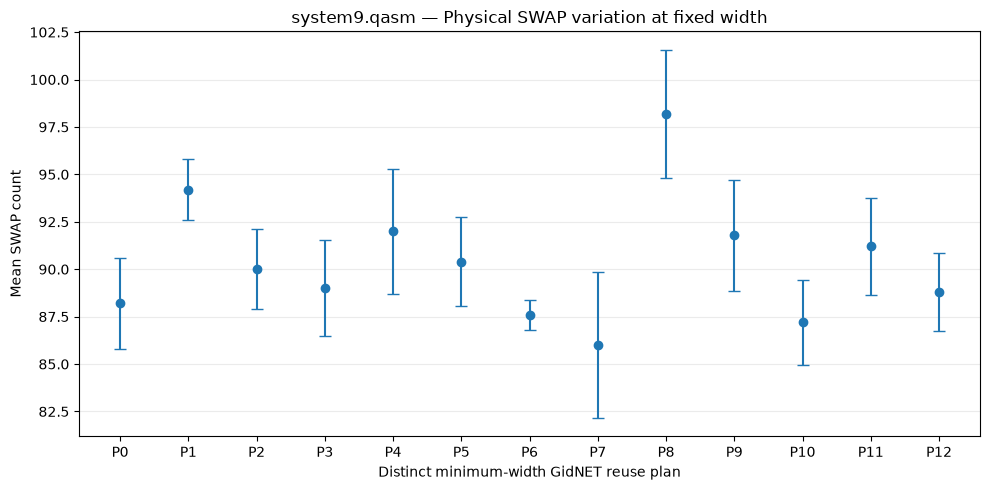

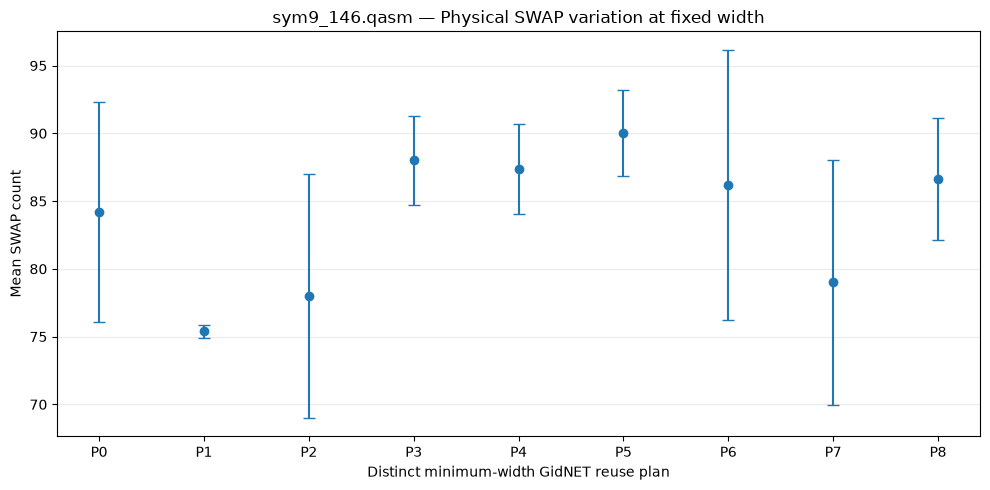

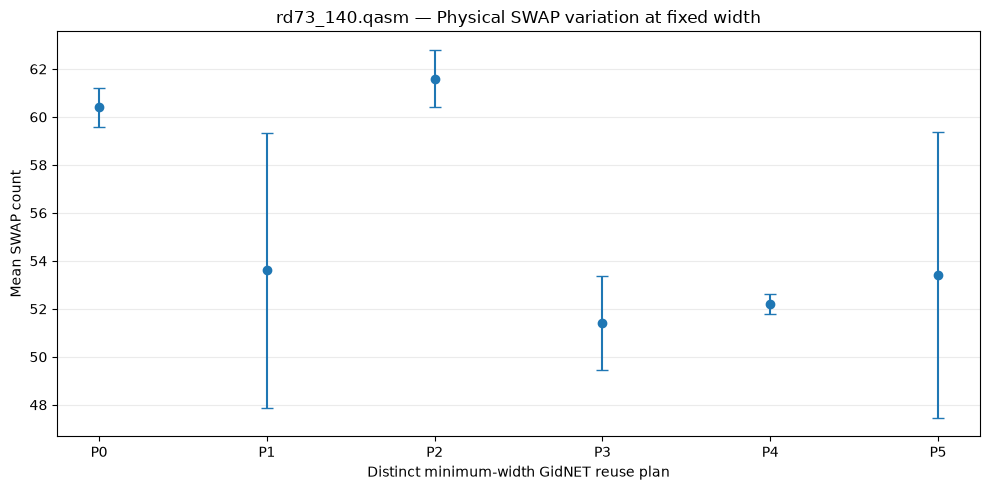

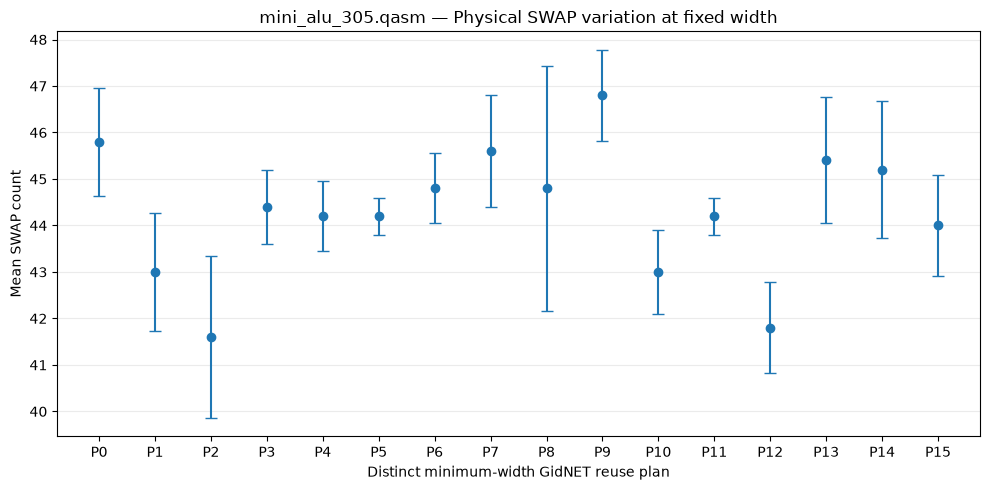

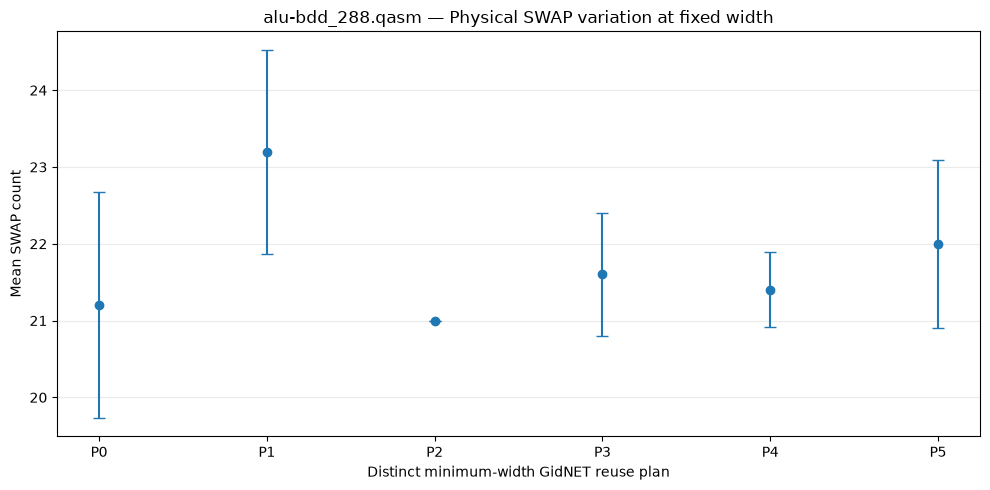

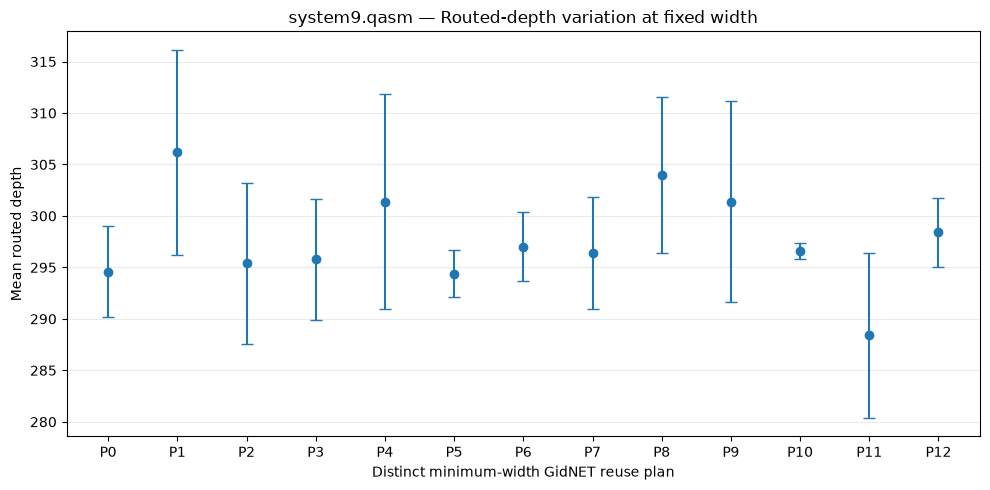

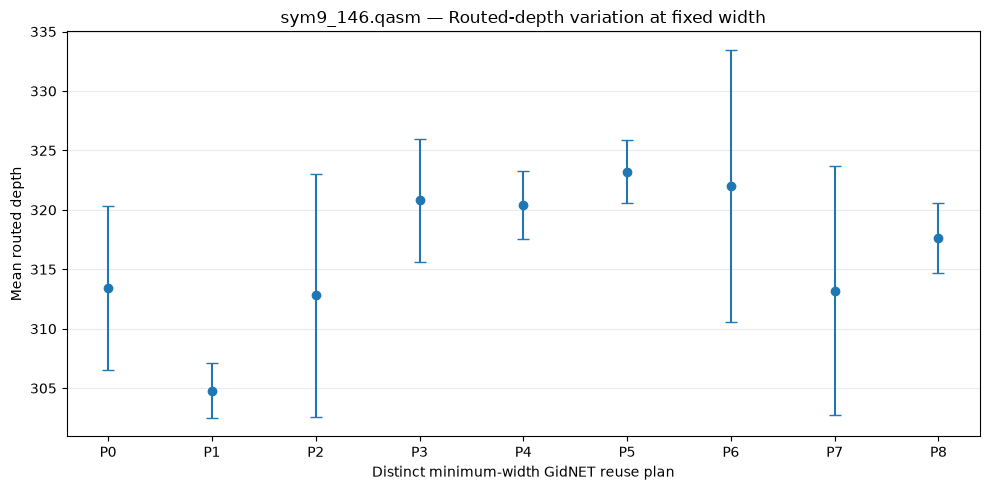

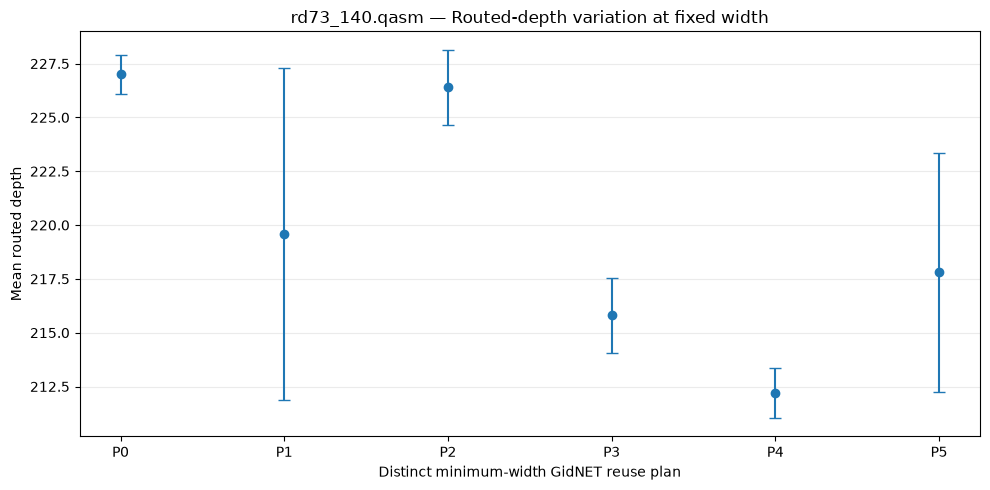

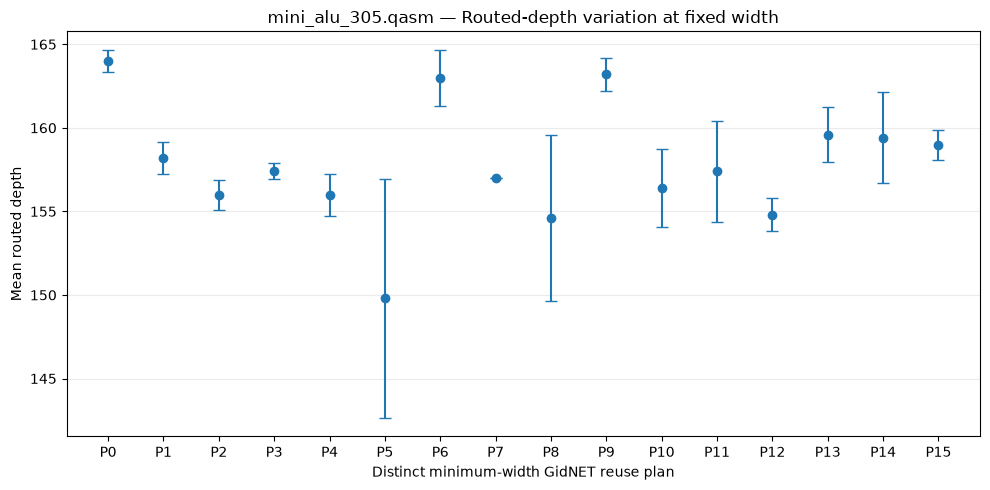

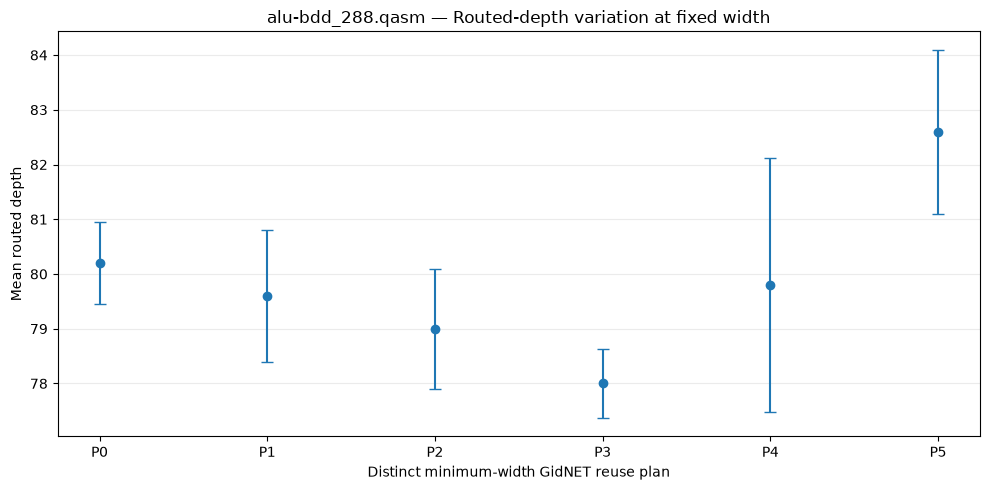

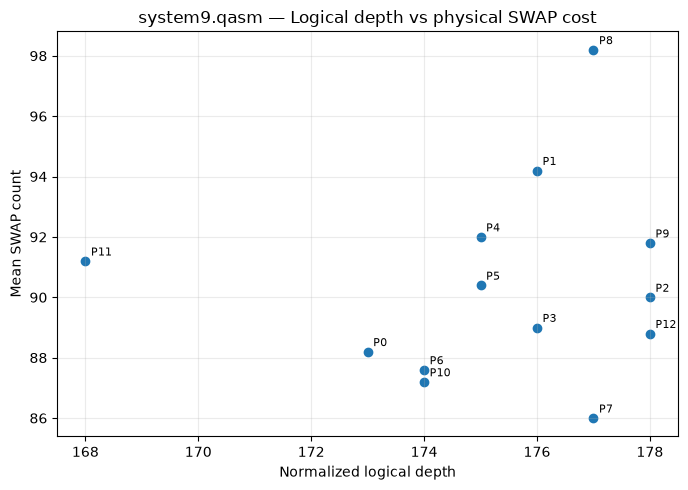

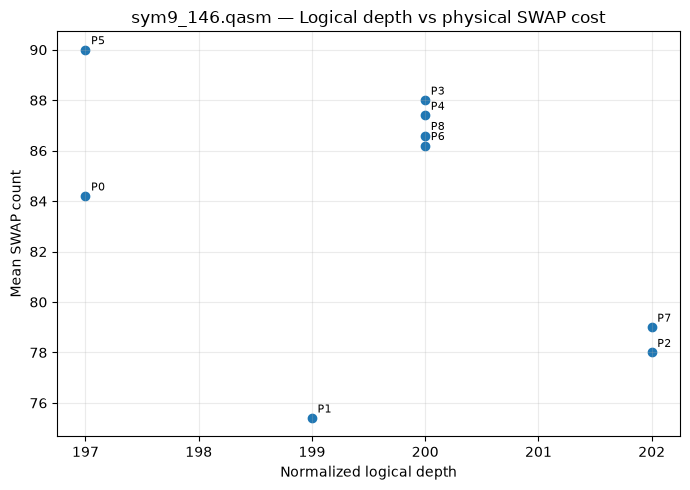

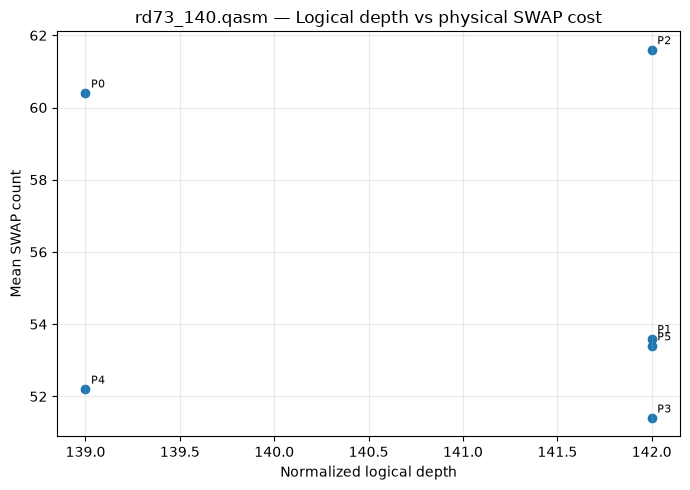

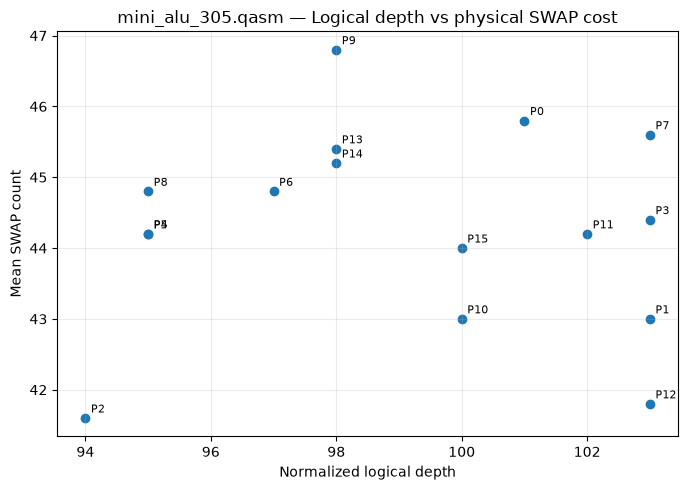

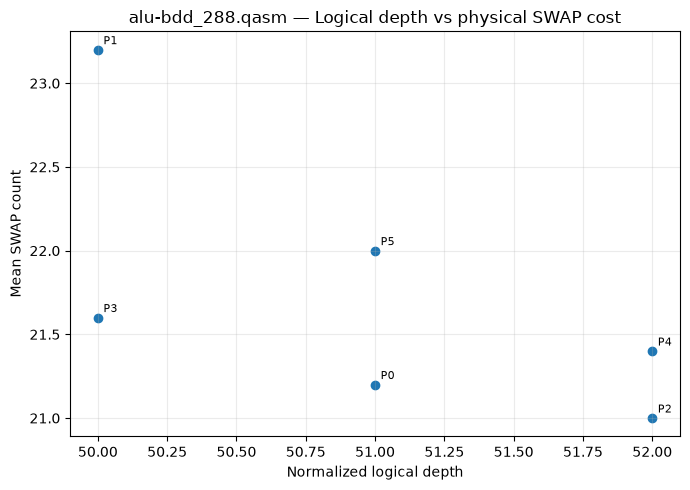

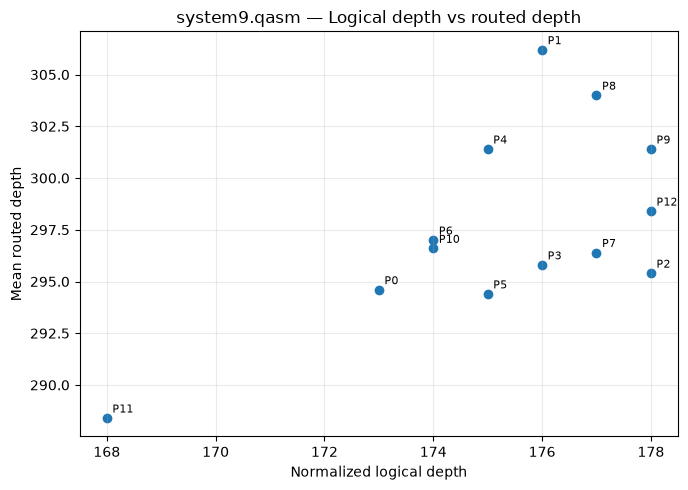

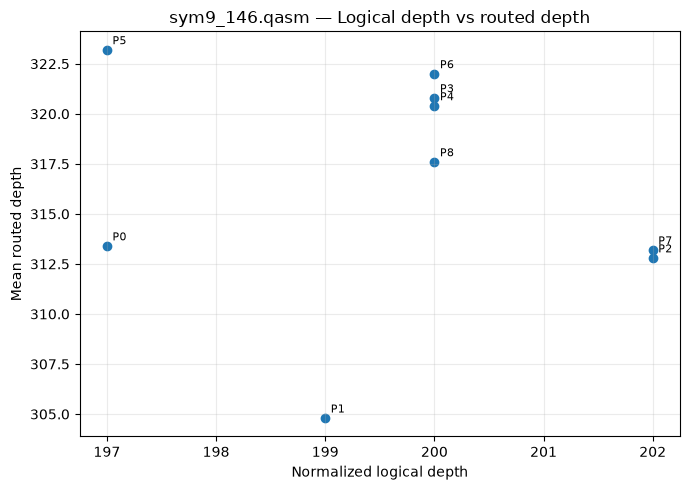

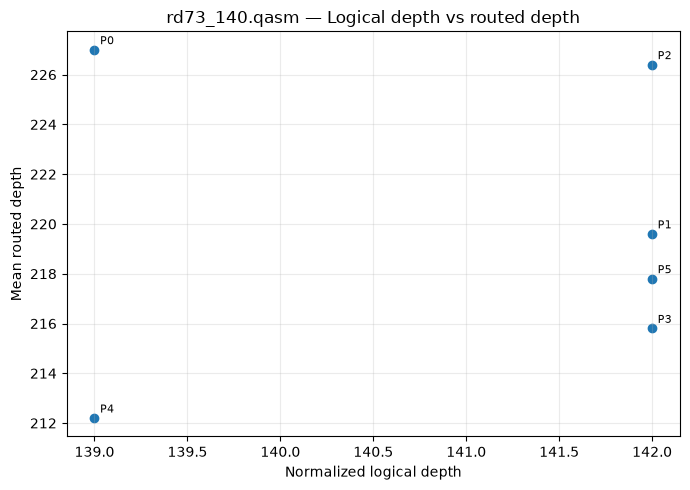

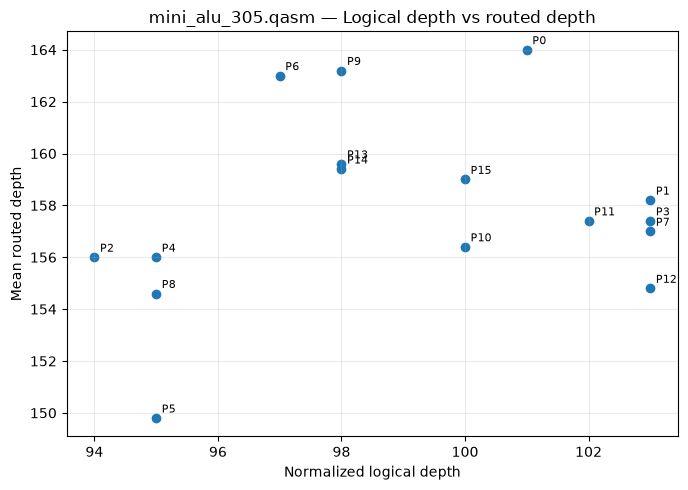

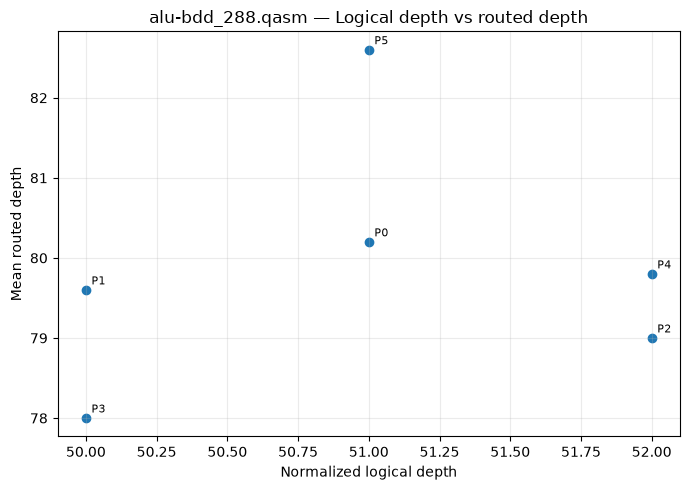

,circuit,num_unique_plans,pearson_logical_depth_vs_swaps,spearman_logical_depth_vs_swaps,pearson_logical_depth_vs_routed_depth,spearman_logical_depth_vs_routed_depth
0,alu-bdd_288.qasm,6,-0.673633,-0.717137,0.173980,0.239046
1,mini_alu_305.qasm,16,-0.024718,0.002996,0.213433,0.220331
2,rd73_140.qasm,6,-0.152483,0.000000,0.026322,0.000000
3,sym9_146.qasm,9,-0.438479,-0.298660,-0.154398,-0.298660
4,system9.qasm,13,0.115180,0.188901,0.626205,0.440911


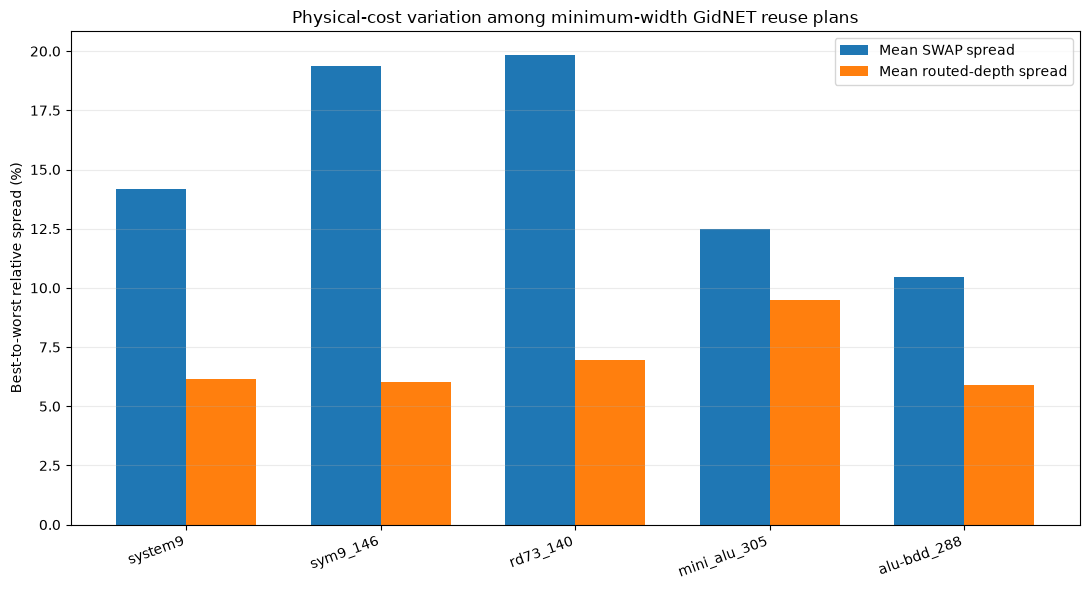

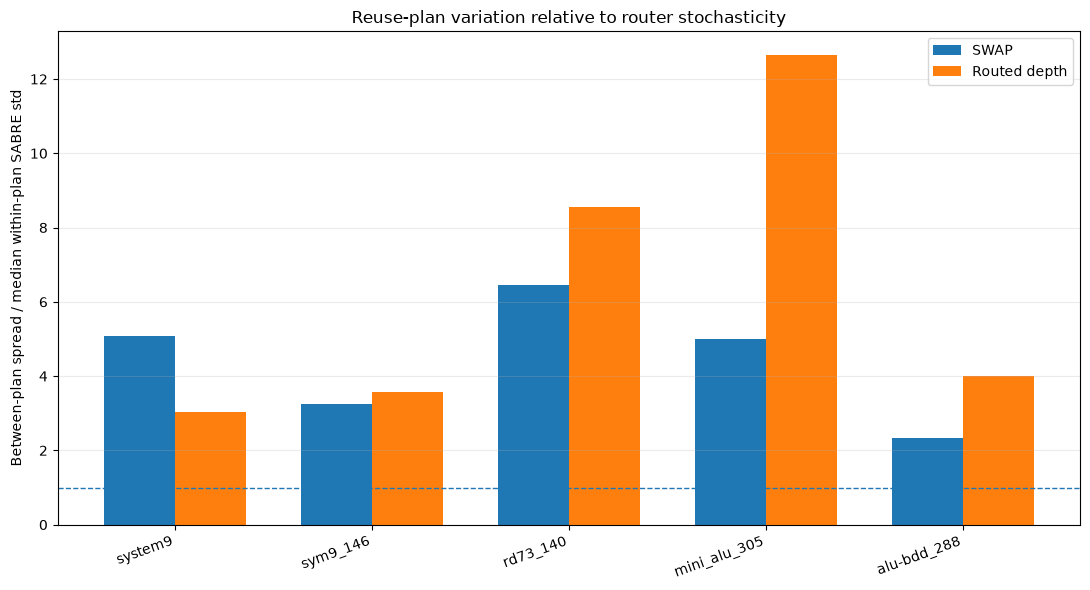

,circuit,best_swap_plan,best_mean_swaps,worst_swap_plan,worst_mean_swaps,best_depth_plan,best_mean_routed_depth,worst_depth_plan,worst_mean_routed_depth
0,alu-bdd_288.qasm,P2,21.0,P1,23.2,P3,78.0,P5,82.6
1,mini_alu_305.qasm,P2,41.6,P9,46.8,P5,149.8,P0,164.0
2,rd73_140.qasm,P3,51.4,P2,61.6,P4,212.2,P0,227.0
3,sym9_146.qasm,P1,75.4,P5,90.0,P1,304.8,P5,323.2
4,system9.qasm,P7,86.0,P8,98.2,P11,288.4,P1,306.2


,circuit,best_swap_plan,best_depth_plan,same_best_plan_for_swap_and_depth
0,alu-bdd_288.qasm,P2,P3,False
1,mini_alu_305.qasm,P2,P5,False
2,rd73_140.qasm,P3,P4,False
3,sym9_146.qasm,P1,P1,True
4,system9.qasm,P7,P11,False


,num_circuits,total_unique_plans,total_physical_routing_runs,mean_relative_swap_spread_pct,median_relative_swap_spread_pct,min_relative_swap_spread_pct,max_relative_swap_spread_pct,mean_relative_depth_spread_pct,median_relative_depth_spread_pct,min_relative_depth_spread_pct,max_relative_depth_spread_pct,circuits_swap_spread_above_router_noise,circuits_depth_spread_above_router_noise
0,5,50,250,15.273998,14.186047,10.47619,19.844358,6.912005,6.171983,5.897436,9.479306,5,5


EXPERIMENT 1 — FINAL SUMMARY
Benchmarks: 5
Distinct minimum-width reuse plans: 50
Physical routing evaluations: 250

Relative SWAP spread:
  min = 10.48%
  max = 19.84%
  mean = 15.27%

Relative routed-depth spread:
  min = 5.90%
  max = 9.48%
  mean = 6.91%

Spread larger than median within-plan SABRE variation:
  SWAP: 5 / 5
  Routed depth: 5 / 5

Saved files:
C:\Users\ASUS\Documents\Quantum computing\Qiskit\GidNET-Qubit-Reuse-Algorithm\experiment1_results


In [59]:
# ============================================================
# Experiment 1 — Final Analysis, Tables, and Plots
# ============================================================


# %%
# ============================================================
# 1. Imports and output directories
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


OUTPUT_DIR = Path(".") / "experiment1_results"
FIGURE_DIR = OUTPUT_DIR / "figures"

OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)

print("Results directory:", OUTPUT_DIR.resolve())
print("Figures directory:", FIGURE_DIR.resolve())


# %%
# ============================================================
# 2. Rebuild combined tables if necessary
# ============================================================
#
# This assumes these result dictionaries already exist:
#
# system9_result
# sym9_result
# rd73_result
# mini_alu_result
# alu_bdd_result
#
# If they already exist, this simply rebuilds the combined tables.


all_results_dict = {
    "system9": system9_result,
    "sym9_146": sym9_result,
    "rd73_140": rd73_result,
    "mini_alu_305": mini_alu_result,
    "alu-bdd_288": alu_bdd_result,
}


all_raw = pd.concat(
    [
        result["raw"]
        for result in all_results_dict.values()
    ],
    ignore_index=True
)


all_plan_summary = pd.concat(
    [
        result["plan_summary"]
        for result in all_results_dict.values()
    ],
    ignore_index=True
)


all_circuit_summary = pd.concat(
    [
        result["circuit_summary"]
        for result in all_results_dict.values()
    ],
    ignore_index=True
)


print("Raw rows:", len(all_raw))
print("Plan-summary rows:", len(all_plan_summary))
print("Circuit-summary rows:", len(all_circuit_summary))


# %%
# ============================================================
# 3. Add final derived metrics
# ============================================================

all_circuit_summary["swap_spread_to_router_noise"] = (
    all_circuit_summary["absolute_swap_spread"]
    / all_circuit_summary["median_within_plan_swap_std"]
)

all_circuit_summary["depth_spread_to_router_noise"] = (
    all_circuit_summary["absolute_routed_depth_spread"]
    / all_circuit_summary["median_within_plan_depth_std"]
)

# Percentage versions for readability
all_circuit_summary["relative_swap_spread_pct"] = (
    100 * all_circuit_summary["relative_swap_spread"]
)

all_circuit_summary["relative_routed_depth_spread_pct"] = (
    100 * all_circuit_summary["relative_routed_depth_spread"]
)


# %%
# ============================================================
# 4. Final integrity / sanity checks
# ============================================================

expected_circuits = {
    "system9.qasm",
    "sym9_146.qasm",
    "rd73_140.qasm",
    "mini_alu_305.qasm",
    "alu-bdd_288.qasm",
}

assert set(all_circuit_summary["circuit"]) == expected_circuits

assert len(all_circuit_summary) == 5

assert all_raw["circuit"].nunique() == 5
assert all_plan_summary["circuit"].nunique() == 5

# Every plan should have exactly 5 routing trials
routing_trials_per_plan = (
    all_raw
    .groupby(["circuit", "plan_id"])
    ["routing_seed"]
    .nunique()
)

assert routing_trials_per_plan.eq(5).all()

# All routing seeds should be exactly 42..46
expected_routing_seeds = {42, 43, 44, 45, 46}

for (circuit, plan_id), group in all_raw.groupby(
    ["circuit", "plan_id"]
):
    assert set(group["routing_seed"]) == expected_routing_seeds

# All plans inside each circuit must have the same width
width_counts = (
    all_plan_summary
    .groupby("circuit")["width"]
    .nunique()
)

assert width_counts.eq(1).all()

# Total unique plans
assert len(all_plan_summary) == 50

# Total routing evaluations:
# 50 unique plans * 5 routing seeds
assert len(all_raw) == 250

print("All final sanity checks passed.")


# %%
# ============================================================
# 5. Final compact circuit-level table
# ============================================================

final_circuit_table = all_circuit_summary[
    [
        "circuit",
        "original_active_qubits",
        "fixed_width",
        "gidnet_trials",
        "minimum_width_trials",
        "unique_min_width_plans",
        "best_mean_swaps",
        "worst_mean_swaps",
        "relative_swap_spread_pct",
        "best_mean_routed_depth",
        "worst_mean_routed_depth",
        "relative_routed_depth_spread_pct",
        "swap_spread_to_router_noise",
        "depth_spread_to_router_noise",
    ]
].copy()

final_circuit_table = final_circuit_table.rename(
    columns={
        "original_active_qubits": "active_qubits",
        "unique_min_width_plans": "unique_plans",
        "relative_swap_spread_pct": "swap_spread_pct",
        "relative_routed_depth_spread_pct": "depth_spread_pct",
        "swap_spread_to_router_noise": "swap_spread_noise_ratio",
        "depth_spread_to_router_noise": "depth_spread_noise_ratio",
    }
)

display(final_circuit_table)


# %%
# ============================================================
# 6. Save final CSV files
# ============================================================

all_raw.to_csv(
    OUTPUT_DIR / "experiment1_raw.csv",
    index=False
)

all_plan_summary.to_csv(
    OUTPUT_DIR / "experiment1_plan_summary.csv",
    index=False
)

all_circuit_summary.to_csv(
    OUTPUT_DIR / "experiment1_circuit_summary.csv",
    index=False
)

final_circuit_table.to_csv(
    OUTPUT_DIR / "experiment1_final_table.csv",
    index=False
)

print("Final CSV files saved.")


# %%
# ============================================================
# 7. Helper for correct P0, P1, P2, ..., P10 ordering
# ============================================================

def plan_number(plan_id):
    return int(str(plan_id).replace("P", ""))


def get_sorted_plan_df(circuit_name):
    df = all_plan_summary[
        all_plan_summary["circuit"] == circuit_name
    ].copy()

    df["plan_number"] = (
        df["plan_id"]
        .map(plan_number)
    )

    return (
        df
        .sort_values("plan_number")
        .reset_index(drop=True)
    )


# %%
# ============================================================
# 8. Plot 1:
# Mean SWAP count ± SABRE standard deviation
# for every plan in every circuit
# ============================================================

for circuit_name in all_plan_summary["circuit"].unique():

    df = get_sorted_plan_df(circuit_name)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.errorbar(
        df["plan_id"],
        df["mean_swaps"],
        yerr=df["std_swaps"],
        fmt="o",
        capsize=4
    )

    ax.set_title(
        f"{circuit_name} — Physical SWAP variation at fixed width"
    )

    ax.set_xlabel("Distinct minimum-width GidNET reuse plan")
    ax.set_ylabel("Mean SWAP count")

    ax.grid(
        axis="y",
        alpha=0.25
    )

    fig.tight_layout()

    output_file = (
        FIGURE_DIR
        / f"{Path(circuit_name).stem}_plan_vs_swaps.png"
    )

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# %%
# ============================================================
# 9. Plot 2:
# Mean routed depth ± SABRE standard deviation
# for every plan in every circuit
# ============================================================

for circuit_name in all_plan_summary["circuit"].unique():

    df = get_sorted_plan_df(circuit_name)

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.errorbar(
        df["plan_id"],
        df["mean_routed_depth"],
        yerr=df["std_routed_depth"],
        fmt="o",
        capsize=4
    )

    ax.set_title(
        f"{circuit_name} — Routed-depth variation at fixed width"
    )

    ax.set_xlabel("Distinct minimum-width GidNET reuse plan")
    ax.set_ylabel("Mean routed depth")

    ax.grid(
        axis="y",
        alpha=0.25
    )

    fig.tight_layout()

    output_file = (
        FIGURE_DIR
        / f"{Path(circuit_name).stem}_plan_vs_routed_depth.png"
    )

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# %%
# ============================================================
# 10. Plot 3:
# Normalized logical depth vs mean SWAP count
# ============================================================

for circuit_name in all_plan_summary["circuit"].unique():

    df = all_plan_summary[
        all_plan_summary["circuit"] == circuit_name
    ].copy()

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(
        df["normalized_logical_depth"],
        df["mean_swaps"]
    )

    # Add plan labels
    for _, row in df.iterrows():
        ax.annotate(
            row["plan_id"],
            (
                row["normalized_logical_depth"],
                row["mean_swaps"]
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_title(
        f"{circuit_name} — Logical depth vs physical SWAP cost"
    )

    ax.set_xlabel("Normalized logical depth")
    ax.set_ylabel("Mean SWAP count")

    ax.grid(alpha=0.25)

    fig.tight_layout()

    output_file = (
        FIGURE_DIR
        / f"{Path(circuit_name).stem}_logical_depth_vs_swaps.png"
    )

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# %%
# ============================================================
# 11. Plot 4:
# Normalized logical depth vs mean routed depth
# ============================================================

for circuit_name in all_plan_summary["circuit"].unique():

    df = all_plan_summary[
        all_plan_summary["circuit"] == circuit_name
    ].copy()

    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(
        df["normalized_logical_depth"],
        df["mean_routed_depth"]
    )

    for _, row in df.iterrows():
        ax.annotate(
            row["plan_id"],
            (
                row["normalized_logical_depth"],
                row["mean_routed_depth"]
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8
        )

    ax.set_title(
        f"{circuit_name} — Logical depth vs routed depth"
    )

    ax.set_xlabel("Normalized logical depth")
    ax.set_ylabel("Mean routed depth")

    ax.grid(alpha=0.25)

    fig.tight_layout()

    output_file = (
        FIGURE_DIR
        / f"{Path(circuit_name).stem}_logical_depth_vs_routed_depth.png"
    )

    fig.savefig(
        output_file,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


# %%
# ============================================================
# 12. Correlation analysis:
# Is logical depth enough to explain physical cost?
# ============================================================

correlation_rows = []

for circuit_name, df in all_plan_summary.groupby("circuit"):

    pearson_depth_swap = (
        df["normalized_logical_depth"]
        .corr(
            df["mean_swaps"],
            method="pearson"
        )
    )

    spearman_depth_swap = (
        df["normalized_logical_depth"]
        .corr(
            df["mean_swaps"],
            method="spearman"
        )
    )

    pearson_depth_routed = (
        df["normalized_logical_depth"]
        .corr(
            df["mean_routed_depth"],
            method="pearson"
        )
    )

    spearman_depth_routed = (
        df["normalized_logical_depth"]
        .corr(
            df["mean_routed_depth"],
            method="spearman"
        )
    )

    correlation_rows.append({
        "circuit": circuit_name,
        "num_unique_plans": len(df),

        "pearson_logical_depth_vs_swaps":
            pearson_depth_swap,

        "spearman_logical_depth_vs_swaps":
            spearman_depth_swap,

        "pearson_logical_depth_vs_routed_depth":
            pearson_depth_routed,

        "spearman_logical_depth_vs_routed_depth":
            spearman_depth_routed,
    })


correlation_summary = pd.DataFrame(
    correlation_rows
)

display(correlation_summary)

correlation_summary.to_csv(
    OUTPUT_DIR / "experiment1_depth_correlations.csv",
    index=False
)


# %%
# ============================================================
# 13. Plot 5:
# Relative physical-cost spread across all five circuits
# ============================================================

summary_plot_df = all_circuit_summary.copy()

summary_plot_df["circuit_short"] = (
    summary_plot_df["circuit"]
    .str.replace(".qasm", "", regex=False)
)

x = np.arange(
    len(summary_plot_df)
)

bar_width = 0.36

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - bar_width / 2,
    summary_plot_df["relative_swap_spread_pct"],
    width=bar_width,
    label="Mean SWAP spread"
)

ax.bar(
    x + bar_width / 2,
    summary_plot_df["relative_routed_depth_spread_pct"],
    width=bar_width,
    label="Mean routed-depth spread"
)

ax.set_xticks(x)

ax.set_xticklabels(
    summary_plot_df["circuit_short"],
    rotation=20,
    ha="right"
)

ax.set_ylabel("Best-to-worst relative spread (%)")

ax.set_title(
    "Physical-cost variation among minimum-width GidNET reuse plans"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "all_circuits_relative_physical_spread.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# %%
# ============================================================
# 14. Plot 6:
# Between-plan spread relative to within-plan SABRE variability
# ============================================================

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - bar_width / 2,
    summary_plot_df["swap_spread_to_router_noise"],
    width=bar_width,
    label="SWAP"
)

ax.bar(
    x + bar_width / 2,
    summary_plot_df["depth_spread_to_router_noise"],
    width=bar_width,
    label="Routed depth"
)

ax.axhline(
    y=1.0,
    linestyle="--",
    linewidth=1
)

ax.set_xticks(x)

ax.set_xticklabels(
    summary_plot_df["circuit_short"],
    rotation=20,
    ha="right"
)

ax.set_ylabel(
    "Between-plan spread / median within-plan SABRE std"
)

ax.set_title(
    "Reuse-plan variation relative to router stochasticity"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    FIGURE_DIR / "all_circuits_plan_spread_vs_router_noise.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# %%
# ============================================================
# 15. Best / worst plan table for each circuit
# ============================================================

best_worst_rows = []

for circuit_name, df in all_plan_summary.groupby("circuit"):

    best_swap_row = df.loc[
        df["mean_swaps"].idxmin()
    ]

    worst_swap_row = df.loc[
        df["mean_swaps"].idxmax()
    ]

    best_depth_row = df.loc[
        df["mean_routed_depth"].idxmin()
    ]

    worst_depth_row = df.loc[
        df["mean_routed_depth"].idxmax()
    ]

    best_worst_rows.append({
        "circuit": circuit_name,

        "best_swap_plan":
            best_swap_row["plan_id"],

        "best_mean_swaps":
            best_swap_row["mean_swaps"],

        "worst_swap_plan":
            worst_swap_row["plan_id"],

        "worst_mean_swaps":
            worst_swap_row["mean_swaps"],

        "best_depth_plan":
            best_depth_row["plan_id"],

        "best_mean_routed_depth":
            best_depth_row["mean_routed_depth"],

        "worst_depth_plan":
            worst_depth_row["plan_id"],

        "worst_mean_routed_depth":
            worst_depth_row["mean_routed_depth"],
    })


best_worst_plan_table = pd.DataFrame(
    best_worst_rows
)

display(best_worst_plan_table)

best_worst_plan_table.to_csv(
    OUTPUT_DIR / "experiment1_best_worst_plans.csv",
    index=False
)


# %%
# ============================================================
# 16. Check whether the same plan is best for both objectives
# ============================================================

best_worst_plan_table[
    "same_best_plan_for_swap_and_depth"
] = (
    best_worst_plan_table["best_swap_plan"]
    ==
    best_worst_plan_table["best_depth_plan"]
)

display(
    best_worst_plan_table[
        [
            "circuit",
            "best_swap_plan",
            "best_depth_plan",
            "same_best_plan_for_swap_and_depth"
        ]
    ]
)


# %%
# ============================================================
# 17. Aggregate descriptive statistics across the five circuits
# ============================================================

aggregate_summary = pd.DataFrame([{

    "num_circuits":
        len(all_circuit_summary),

    "total_unique_plans":
        len(all_plan_summary),

    "total_physical_routing_runs":
        len(all_raw),

    "mean_relative_swap_spread_pct":
        all_circuit_summary[
            "relative_swap_spread_pct"
        ].mean(),

    "median_relative_swap_spread_pct":
        all_circuit_summary[
            "relative_swap_spread_pct"
        ].median(),

    "min_relative_swap_spread_pct":
        all_circuit_summary[
            "relative_swap_spread_pct"
        ].min(),

    "max_relative_swap_spread_pct":
        all_circuit_summary[
            "relative_swap_spread_pct"
        ].max(),

    "mean_relative_depth_spread_pct":
        all_circuit_summary[
            "relative_routed_depth_spread_pct"
        ].mean(),

    "median_relative_depth_spread_pct":
        all_circuit_summary[
            "relative_routed_depth_spread_pct"
        ].median(),

    "min_relative_depth_spread_pct":
        all_circuit_summary[
            "relative_routed_depth_spread_pct"
        ].min(),

    "max_relative_depth_spread_pct":
        all_circuit_summary[
            "relative_routed_depth_spread_pct"
        ].max(),

    "circuits_swap_spread_above_router_noise":
        int(
            (
                all_circuit_summary[
                    "swap_spread_to_router_noise"
                ] > 1
            ).sum()
        ),

    "circuits_depth_spread_above_router_noise":
        int(
            (
                all_circuit_summary[
                    "depth_spread_to_router_noise"
                ] > 1
            ).sum()
        ),
}])


display(aggregate_summary)

aggregate_summary.to_csv(
    OUTPUT_DIR / "experiment1_aggregate_summary.csv",
    index=False
)


# %%
# ============================================================
# 18. Final human-readable console summary
# ============================================================

print("=" * 70)
print("EXPERIMENT 1 — FINAL SUMMARY")
print("=" * 70)

print(
    f"Benchmarks: "
    f"{len(all_circuit_summary)}"
)

print(
    f"Distinct minimum-width reuse plans: "
    f"{len(all_plan_summary)}"
)

print(
    f"Physical routing evaluations: "
    f"{len(all_raw)}"
)

print("\nRelative SWAP spread:")

print(
    f"  min = "
    f"{all_circuit_summary['relative_swap_spread_pct'].min():.2f}%"
)

print(
    f"  max = "
    f"{all_circuit_summary['relative_swap_spread_pct'].max():.2f}%"
)

print(
    f"  mean = "
    f"{all_circuit_summary['relative_swap_spread_pct'].mean():.2f}%"
)

print("\nRelative routed-depth spread:")

print(
    f"  min = "
    f"{all_circuit_summary['relative_routed_depth_spread_pct'].min():.2f}%"
)

print(
    f"  max = "
    f"{all_circuit_summary['relative_routed_depth_spread_pct'].max():.2f}%"
)

print(
    f"  mean = "
    f"{all_circuit_summary['relative_routed_depth_spread_pct'].mean():.2f}%"
)

print("\nSpread larger than median within-plan SABRE variation:")

print(
    "  SWAP:",
    int(
        (
            all_circuit_summary[
                "swap_spread_to_router_noise"
            ] > 1
        ).sum()
    ),
    "/",
    len(all_circuit_summary)
)

print(
    "  Routed depth:",
    int(
        (
            all_circuit_summary[
                "depth_spread_to_router_noise"
            ] > 1
        ).sum()
    ),
    "/",
    len(all_circuit_summary)
)

print("\nSaved files:")
print(OUTPUT_DIR.resolve())

print("=" * 70)